# Geometry

Vier Wege durch die Geometrie, durchgerechnet mit numpy, scipy und sympy: die Vektoranalysis mit Gradient, Divergenz, Rotation und den Integralsätzen bis zu Magnetfeldern, Quantenwirbeln und Berry-Krümmung; die Tensoranalysis gekrümmter Räume von der Kugel bis zur Lichtablenkung an der Sonne; die projektive Geometrie von Fluchtpunkten über Computer Vision und endliche Ebenen bis zur Bloch-Kugel; und Quadriken und elliptische Kurven von Keplerbahnen bis zur Kryptographie und Shors Algorithmus. Daten werden nicht geladen. Der Code steht in [`code/geometry/`](https://github.com/deltorobarba/science/tree/main/code/geometry), ein Modul je Teil (`vectorcalc.py`, `tensors.py`, `projective.py`, `quadrics.py`); hier stehen nur die Aufrufe und die Bilder. Die Funktionen eines Moduls reichen ihre Zwischenergebnisse weiter und laufen deshalb in der Reihenfolge des Notebooks.

**Der rote Faden**

Die vier Teile fragen, was an einer Form wesentlich ist, also was sich unter den erlaubten Abbildungen nicht ändert.

- **Schritte 1 bis 14, Vektoranalysis:** Felder im flachen Raum. Die Integralsätze sagen, dass das Innere eines Gebiets durch seinen Rand bestimmt ist; um Löcher und Nullstellen entstehen ganzzahlige Größen wie quantisierte Wirbel und Chern-Zahlen.
- **Schritte 15 bis 22, Tensoren:** gekrümmte Räume, von innen gemessen. Krümmung zeigt sich im Paralleltransport, Gauß-Bonnet verbindet sie mit der Topologie, und Geodäten um die Sonne ergeben Lichtablenkung und Periheldrehung.
- **Schritte 23 bis 36, projektive Geometrie:** Nur Geraden und Doppelverhältnis bleiben. Das erklärt Perspektive und Computer Vision, und der Zustandsraum der Quantenmechanik ist selbst ein projektiver Raum.
- **Schritte 37 bis 47, Quadriken und elliptische Kurven:** Gleichungen vom Grad 2 werden durch Eigenwerte vollständig verstanden; vom Grad 3 an entsteht eine Gruppe, auf der heutige Kryptographie beruht.

Die gemeinsame Lehre: Geometrie ist das Studium der Invarianten. Ob Fluss durch einen Rand, Krümmung, Doppelverhältnis oder Signatur: Wer weiß, was erhalten bleibt, kann rechnen, ohne Koordinaten zu wählen.

In [1]:
import sys
import urllib.request
import importlib.util
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "geometry"
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir(parents=True)
    for f in ["vectorcalc.py", "tensors.py", "projective.py", "quadrics.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/geometry/{f}", CODE / f)
if "google.colab" not in sys.modules and (importlib.util.find_spec("sympy") is None):
    raise ImportError("Es fehlt eines der Pakete sympy; lokal selbst installieren (conda-forge)")
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import vectorcalc, tensors, projective, quadrics

**1. Vektoranalysis: der Gradient**

Die Vektoranalysis ist die Analysis von Feldern, die jedem Punkt eine Zahl (Temperatur, Potential) oder einen Vektor (Geschwindigkeit, Kraft) zuordnen. Sie hat drei Ableitungen und drei große Integralsätze. Der Gradient eines Skalarfelds zeigt in die Richtung des steilsten Anstiegs; gezeigt an einer Landschaft mit Hügel, Mulde und Sattel.

Die Gradientenpfeile stehen überall senkrecht auf den Höhenlinien und zeigen bergauf. Wo der Gradient null ist, liegen die kritischen Punkte: ein Minimum, ein Maximum und ein Sattel, unterschieden durch die Eigenwerte der zweiten Ableitungen.

kritischer Punkt (-0.6691, -0.0000): f = -0.4052, Eigenwerte der Hesse-Matrix (+0.9552, +1.9000) → Minimum
kritischer Punkt (+0.7525, -0.0000): f = +0.4555, Eigenwerte der Hesse-Matrix (-1.4954, -0.7543) → Maximum
kritischer Punkt (+1.8602, +0.0000): f = +0.2315, Eigenwerte der Hesse-Matrix (-0.0169, +0.5583) → Sattel


Höhenlinie durch p0 = (0.5, 0.4), ein Umlauf: größte Abweichung |f − f(p0)| = 2.6e-13
Gradientenfluss ab p0 endet bei (0.7525, 0.0000), dem Maximum
Richtungsableitung: Differenzenquotient gegen ∇f·u, größte Abweichung 4.5e-11; Maximum 0.4434 bei α = 329°, |∇f| = 0.4434 bei arg ∇f = 329.4°


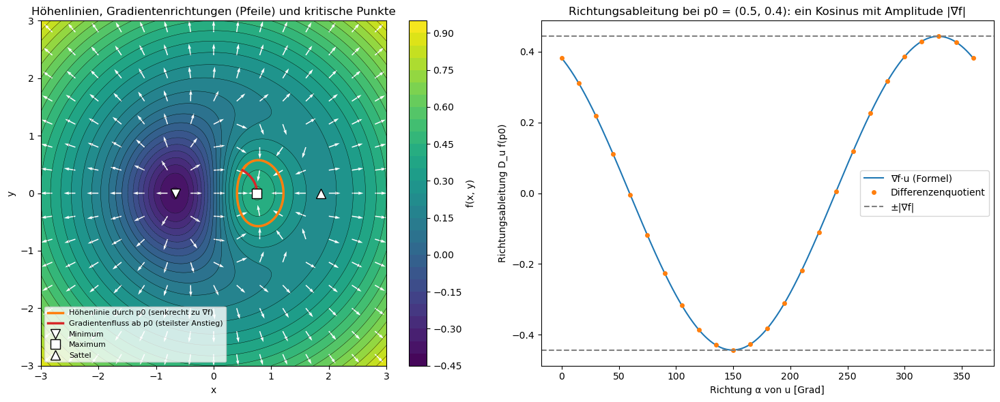

In [2]:
vectorcalc.gradient()

**2. Divergenz und Rotation sehen**

Die Divergenz misst, wie viel aus einem Punkt herausfließt, die Rotation, wie stark das Feld dort wirbelt. Sechs Felder mit ihren Stromlinien.

Die Quelle hat überall Divergenz 2 und keine Rotation, der starre Wirbel umgekehrt. Die Scherung hat nur gerade Stromlinien und trotzdem Rotation −1: Ein Schaufelrad würde oben stärker geschoben als unten und sich drehen. Rotation heißt nicht, dass die Stromlinien Kreise sind.

Quelle (x, y)                div = 2            rot = 0                Gitter gegen exakt (r > 0.3): 2.2e-14


Wirbel (−y, x)               div = 0            rot = 2                Gitter gegen exakt (r > 0.3): 2.2e-14


Scherung (y, 0)              div = 0            rot = -1               Gitter gegen exakt (r > 0.3): 1.1e-14


Dehnung (x, −y)              div = 0            rot = 0                Gitter gegen exakt (r > 0.3): 1.1e-14


Potentialwirbel (−y, x)/r²   div = 0            rot = 0                Gitter gegen exakt (r > 0.3): 9.6e-02


Zellen (sin y, sin x)        div = 0            rot = cos(x) - cos(y)  Gitter gegen exakt (r > 0.3): 9.2e-03


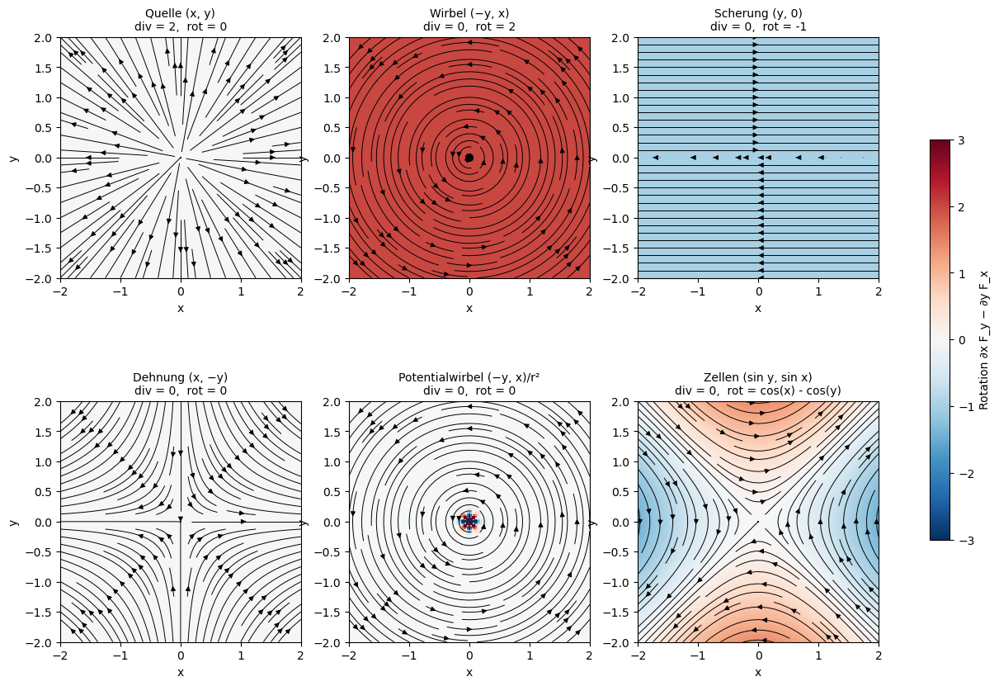

In [3]:
vectorcalc.div_curl()

**3. Kurvenintegrale**

Die Arbeit eines Felds entlang eines Weges, für drei Wege zwischen denselben Punkten, einmal für ein Gradientenfeld und einmal für einen Wirbel.

Für das Gradientenfeld ergeben alle Wege dieselbe Arbeit, 2.9092974268 = φ(Ende) − φ(Anfang), auch die Schleife. Für den Wirbel hängt das Ergebnis vom Weg ab. Um ein Loch herum kann auch ein wirbelfreies Feld eine Zirkulation haben: Das Loch trägt die Information.

φ(1, 2) − φ(0, 0) = 2 + sin 2 = 2.9092974268
Gerade    ∫∇φ·dr = 2.9092974268   ∫(−y, x)·dr = +0.000000
Parabel   ∫∇φ·dr = 2.9092974268   ∫(−y, x)·dr = +0.666667
Schleife  ∫∇φ·dr = 2.9092974268   ∫(−y, x)·dr = +0.309483
Potentialwirbel, Kreis r = 1 um 0            : ∮ F·dr / 2π = +1.000000000000
Potentialwirbel, Ellipse um 0, verschoben    : ∮ F·dr / 2π = +1.000000000000
Potentialwirbel, Kreis um (2, 0), r = 0.7    : ∮ F·dr / 2π = +0.000000000000
Potentialwirbel, zweimal um 0                : ∮ F·dr / 2π = +2.000000000000
Potentialwirbel, Kreis um 0 im Uhrzeigersinn : ∮ F·dr / 2π = -1.000000000000


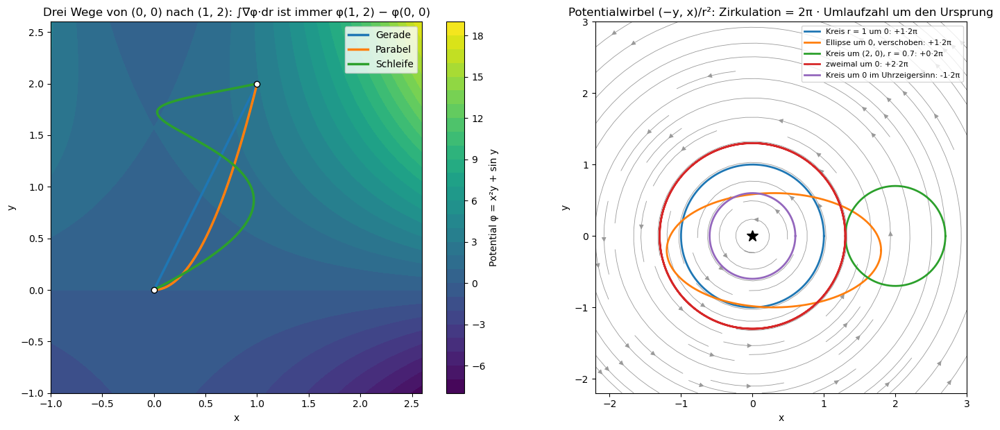

In [4]:
vectorcalc.line_integrals()

**4. Satz von Green**

Die Zirkulation um den Rand eines Gebiets ist das Integral der Rotation über das Innere; ebenso ist der Fluss durch den Rand das Integral der Divergenz. Daraus folgt auch die Fläche aus dem Rand allein.

Zirkulation und Flächenintegral stimmen auf zwölf Stellen überein (10.742292658575), ebenso Fluss und Divergenz. Die Fläche eines Vielecks aus seinen Ecken (Schnürsenkel-Formel) ist genau dieser Satz.

Fläche der Blume: exakt π I₀(1) = 3.977463260506; Trapezregel N = 40: 3.977463260506; Polygon N = 40: 3.913103437685
rot F = 3*x**2 - x + 3*y**2 + sin(y):  ∮ F·dr = 10.742292658575,  ∬ rot F dA = 10.742292658575
div F = x*cos(y) + y:  ∮ F·n ds = 0.353847188464,  ∬ div F dA = 0.353847188464


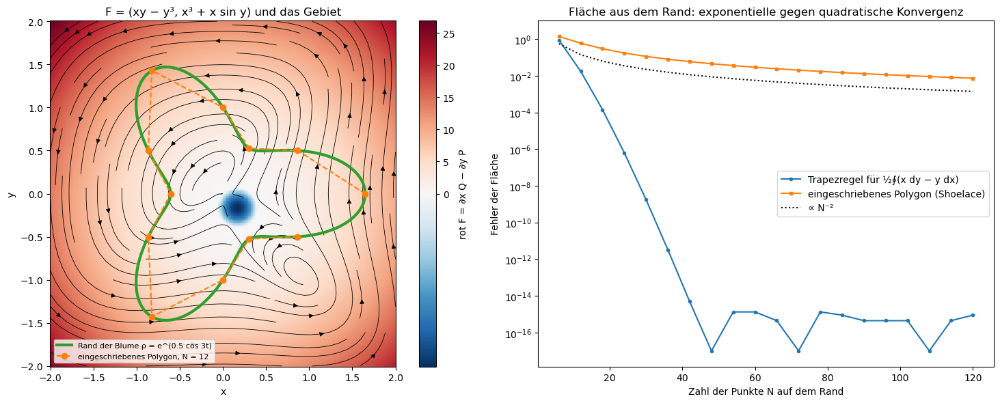

In [5]:
vectorcalc.green()

**5. Gaußscher Integralsatz: der Fluss einer Punktladung**

Der Fluss des Felds einer Punktladung durch eine geschlossene Fläche ist 4π, wenn die Ladung innen liegt, sonst 0. Berechnet wird er numerisch für eine Ladung immer näher an der Oberfläche.

Der Grenzwert ist immer 4π; nur die Rechnung wird schwerer: Bei 0.7 Abstand genügen etwa 20 Stützstellen pro Richtung, bei 0.03 braucht man 120. Liegt die Ladung außen, heben sich Ein- und Ausfluss auf.

Ladung im Mittelpunkt                : Fluss/4π durch die Einheitskugel +1.0000000000, durch den Würfel [−1, 1]³ +1.0000000000
Ladung bei (0.3, 0.2, 0.1)           : Fluss/4π durch die Einheitskugel +1.0000000000, durch den Würfel [−1, 1]³ +1.0000000000


Ladung bei (0, 0, 0.9), nahe am Rand : Fluss/4π durch die Einheitskugel +1.0000000000, durch den Würfel [−1, 1]³ +0.9999999999
Ladung bei (0, 0, 1.5), außen        : Fluss/4π durch die Einheitskugel +0.0000000000, durch den Würfel [−1, 1]³ +0.0000000000
F = (x³, y³, z³): Fluss durch die Einheitskugel 7.539822368616, ∫div F dV = 12π/5 = 7.539822368616; durch den Würfel 24.000000000000, ∫div F dV = 24
Dipol, Kugel um +     : Fluss/4π = +1.0000000000


Dipol, Kugel um −     : Fluss/4π = -1.0000000000
Dipol, Kugel um beide : Fluss/4π = +0.0000000000


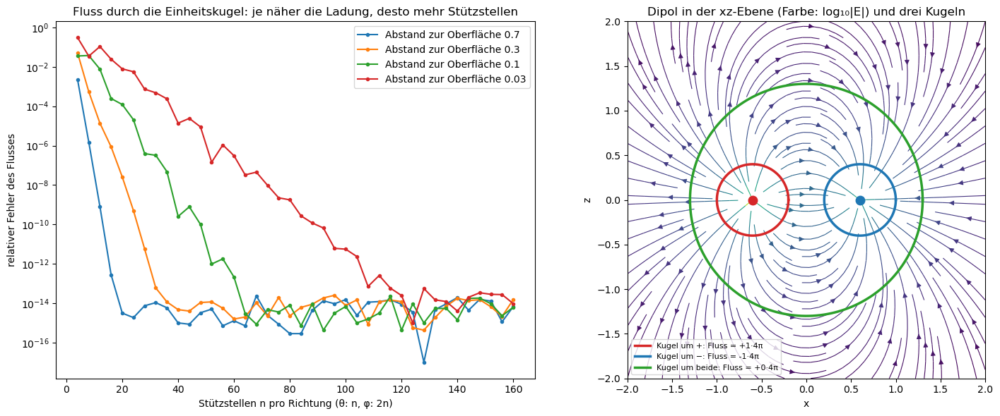

In [6]:
vectorcalc.gauss()

**6. Satz von Stokes**

Der Fluss der Rotation durch eine Fläche hängt nur von ihrem Rand ab. Fünf ganz verschiedene Flächen haben denselben Einheitskreis als Rand.

Flach, halbkugelförmig, hoch gewölbt, durchhängend und verbeult: Alle fünf Flüsse sind 4.712389 = 3π/2, gleich der Zirkulation entlang des Kreises, auf zwölf Stellen. Die Divergenz einer Rotation ist null; deshalb kann der Fluss nicht von der Fläche abhängen.

rot F = [-2*x*z + x*exp(x*y), -y*exp(x*y) + y, 3*x**2 + 3*y**2 + z**2 - z]   div rot F = 0
Zirkulation entlang des Einheitskreises: 4.712388980385  (3π/2 = 4.712388980385)
Kreisscheibe              : Fluss von rot F = 4.712388980385
Halbkugel                 : Fluss von rot F = 4.712388980385
Paraboloid z = 2(1 − ρ²)  : Fluss von rot F = 4.712388980385
Schale z = −1.5(1 − ρ²)   : Fluss von rot F = 4.712388980385
verbeulte Kappe           : Fluss von rot F = 4.712388980385
geschlossene Einheitskugel  : Fluss von rot F = -9.1e-14


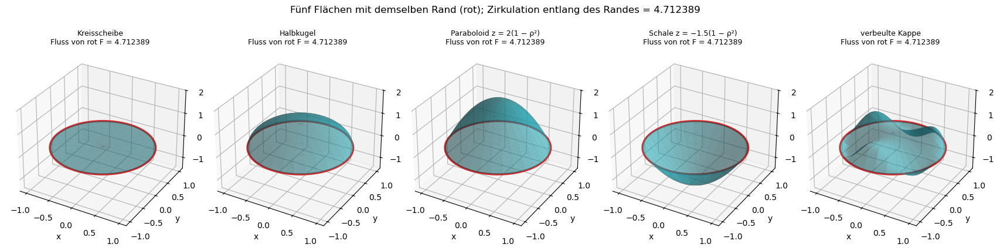

In [7]:
vectorcalc.stokes()

**7. Krummlinige Koordinaten**

In Polar-, Zylinder- und Kugelkoordinaten zeigen die Basisvektoren an jedem Ort in andere Richtungen. Die Operatoren bekommen deshalb Skalenfaktoren und Zusatzterme.

sympy leitet die Skalenfaktoren aus der Koordinatenabbildung her und baut daraus Gradient, Divergenz und Laplace-Operator; an bekannten Feldern stimmen sie. Der Laplace-Operator einer Glockenkurve in Kugelkoordinaten hat den Zusatzterm (2/r) f′, den man nicht vergessen darf.

Metrik in Kugelkoordinaten: [[1, 0, 0], [0, r**2, 0], [0, 0, r**2*sin(theta)**2]]   det der Jacobi-Matrix: r**2*sin(theta)


Δf kartesisch gegen Kugelformel, f = x²yz + z³ + eˣy:  Differenz = 0
Δ rⁿ = n*r**(n - 2)*(n + 1)   Δ(1/r) = 0   div(e_r/r²) = 0


Δ(r² Y₂¹) = 0   r² ΔY₂¹ / Y₂¹ = -6 = −l(l + 1) mit l = 2
Zylinder: rot(e_φ/ρ) = [0, 0, 0]  div(e_ρ/ρ) = 0  Δ ln ρ = 0  rot(starre Drehung ωρ e_φ) = [0, 0, 2*omega]
Δ e^(−r²): 7-Punkte-Stern (h = 0.050) gegen Kugelformel, größte Abweichung 7.5e-03


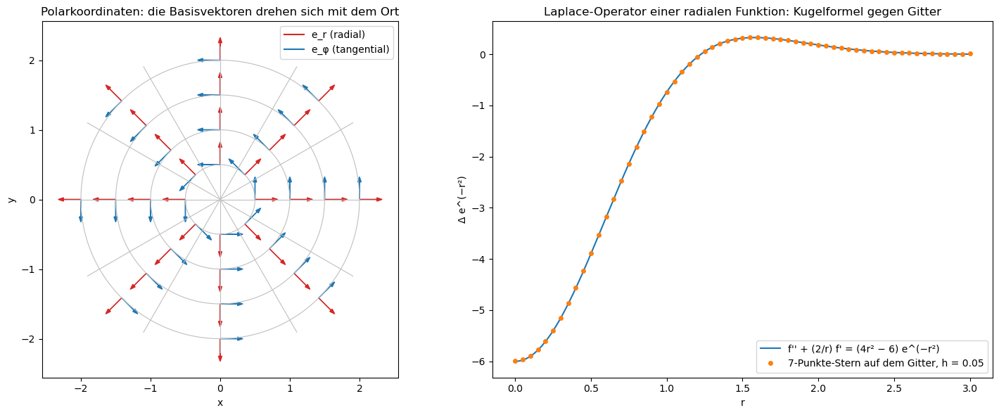

In [8]:
vectorcalc.curvilinear()

**8. Die Identitäten rot grad = 0 und div rot = 0, auch auf dem Gitter**

Die beiden Identitäten gelten exakt, weil gemischte Ableitungen vertauschen. Geprüft wird, ob sie auch für Differenzen auf einem Gitter gelten.

Mit denselben Differenzenoperatoren gelten sie auch auf dem Gitter exakt, bis auf Rundung (10⁻¹⁵). Wählt man für den Laplace-Operator einen anderen Differenzenstern, bleibt ein Fehler, der mit h² fällt. Diskrete Operatoren, die die Struktur der kontinuierlichen erhalten, ersparen Fehler.

rot grad f                       = [0, 0, 0]
div rot A                        = 0
rot rot A − (grad div A − ΔA)    = [0, 0, 0]
div(fA) − (∇f·A + f div A)       = 0
rot(fA) − (∇f × A + f rot A)     = [0, 0, 0]


Gitter: rot grad f                               n=12: 4.4e-16  n=24: 8.9e-16  n=48: 1.9e-15  n=96: 4.4e-15
Gitter: div rot A                                n=12: 8.9e-16  n=24: 2.0e-15  n=48: 4.3e-15  n=96: 9.8e-15
Gitter: rot rot A − (grad div A − Σ DᵢDᵢ A)      n=12: 1.8e-15  n=24: 2.1e-15  n=48: 4.7e-15  n=96: 9.3e-15
Gitter: rot rot A − (grad div A − Δ₃ A)          n=12: 1.3e+00  n=24: 4.1e-01  n=48: 1.1e-01  n=96: 2.7e-02


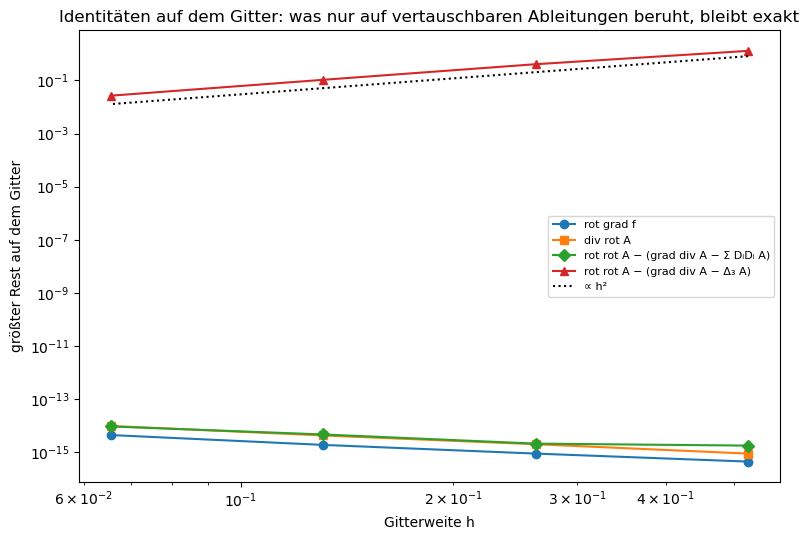

In [9]:
vectorcalc.identities()

**9. Helmholtz-Zerlegung mit der FFT**

Jedes Feld zerfällt in einen wirbelfreien Teil (Gradient eines Potentials) und einen quellenfreien Teil (Rotation). Im Fourier-Raum ist das eine Projektion auf die Richtung des Wellenvektors.

Das zusammengesetzte Feld ist ein unübersichtliches Muster aus Quellen und Wirbeln. Die FFT trennt es: Der wirbelfreie Teil läuft von Minima zu Maxima des Potentials ohne geschlossene Schleifen, der quellenfreie Teil kreist. Beide stimmen mit den eingesetzten Teilen überein.

Gradiententeil: Abweichung vom Bauteil 3.6e-15, rot = 5.4e-14
quellenfreier Teil: Abweichung 3.3e-15, div = 3.4e-14
Mittelwert [ 0.2 -0.1]; φ und ψ bis auf Konstanten: 2.7e-15, 1.6e-15
⟨∇φ, ∇⊥ψ⟩ = +1.4e-17;  Mittelwert von |v|² = 3.635000 = 2.500000 (Gradient) + 1.085000 (quellenfrei) + 0.050000 (konstant)


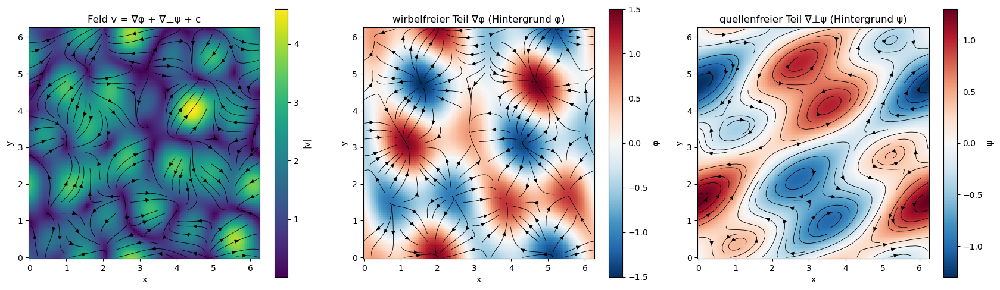

In [10]:
vectorcalc.helmholtz()

**10. Die Laplace-Gleichung**

Lösungen der Laplace-Gleichung sind im Inneren der Mittelwert ihrer Umgebung und nehmen Maximum und Minimum am Rand an. Gelöst wird auf einem Gitter und mit Irrfahrten, die bis zum Rand laufen und dort den Randwert zählen.

Die Gitterlösung hat einen Fehler, der mit h² fällt. Die Mittelwerteigenschaft gilt auf jedem Kreis, und das Maximum liegt am Rand. Der Mittelwert vieler Irrfahrten trifft die Lösung in der Mitte: Die Laplace-Gleichung ist die Gleichung des Random Walk.

n =   7, h = 0.1250: größter Fehler 4.32e-03, max u innen = 0.6770 (Rand: max 1), min u = 1.4e-02
n =  15, h = 0.0625: größter Fehler 1.11e-03, max u innen = 0.8215 (Rand: max 1), min u = 3.4e-03
n =  31, h = 0.0312: größter Fehler 2.78e-04, max u innen = 0.9062 (Rand: max 1), min u = 8.4e-04
n =  63, h = 0.0156: größter Fehler 6.96e-05, max u innen = 0.9519 (Rand: max 1), min u = 2.1e-04
n = 127, h = 0.0078: größter Fehler 1.74e-05, max u innen = 0.9757 (Rand: max 1), min u = 5.2e-05
u (harmonisch)  : Mittel auf dem Kreis r = 0.3 um (0.5, 0.5) = 0.199268407669, Wert im Mittelpunkt = 0.199268407669
x² + y² (Δ = 4) : Mittel auf dem Kreis r = 0.3 um (0.5, 0.5) = 0.590000000000, Wert im Mittelpunkt = 0.500000000000


Irrfahrten (20000): u(0.5, 0.5) ≈ 0.2023 ± 0.0026; Gitterlösung 0.1995; exakt 0.1993


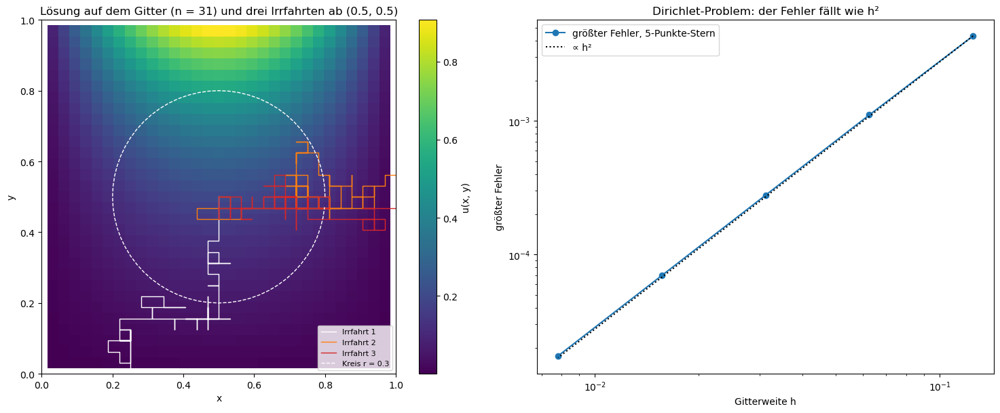

In [11]:
vectorcalc.laplace_equation()

**11. Fluss, Volumen und die Divergenz**

Die Divergenz sagt, wie schnell ein kleines Volumen wächst. Beispiele: ein Tropfen im Phasenraum des Pendels und Volumen in hohen Dimensionen.

Ohne Reibung verzerrt sich der Tropfen zu einer langen Sichel, behält aber seine Fläche (Liouville). Mit Reibung schrumpft er wie e^(−γt), wie die Divergenz −γ verlangt. In hohen Dimensionen, etwa bei Normalizing Flows im maschinellen Lernen, schätzt man die Divergenz mit Zufallsvektoren (Hutchinson): Vektoren aus ±1 streuen dabei viel weniger als gaußsche (0.8 % gegen 4.7 % Fehler mit 16 Proben).

Pendel, γ = 0.0: Fläche/Anfangsfläche bei t = 8: 0.99999990, e^(−γt) = 1.00000000; größte Abweichung über t = 0, 1, …, 8: 9.9e-08


Pendel, γ = 0.25: Fläche/Anfangsfläche bei t = 8: 0.13533528, e^(−γt) = 0.13533528; größte Abweichung über t = 0, 1, …, 8: 1.6e-08


Van der Pol (μ = 1): größte Abweichung |ln det J − ∫div v dt| bis t = 15: 6.4e-11
div v exakt (Spur der Jacobi-Matrix) = 56.293751; εᵀJε aus zwei Auswertungen von v: 57.675931, mit der Matrix: 57.675931


Gauß      : Standardabweichung einer Probe gemessen 10.580, Theorie √Var = 10.695; relativer Fehler mit k = 16 Proben 4.7%
Rademacher: Standardabweichung einer Probe gemessen 1.754, Theorie √Var = 1.750; relativer Fehler mit k = 16 Proben 0.8%


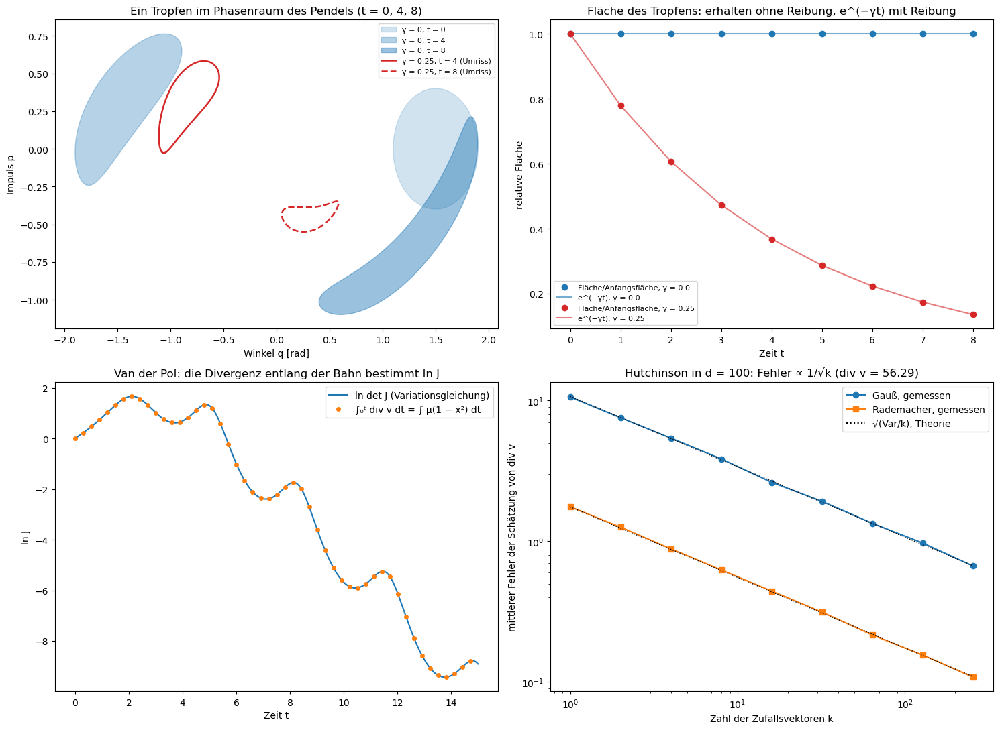

In [12]:
vectorcalc.flux_volume()

**12. Magnetfeld einer Leiterschleife**

Das Feld eines Kreisstroms nach Biot-Savart, mit Prüfungen der Maxwell-Gleichungen: Es hat keine Quellen, und seine Zirkulation um einen Weg ist der umschlossene Strom (Ampère).

Die Feldlinien kreisen um den Draht und laufen gebündelt durch die Mitte, wie bei einem Stabmagneten. Die Divergenz verschwindet bis auf den numerischen Fehler; die Zirkulation ist 1 für Wege, die den Draht einmal umschließen, und 0 für die anderen.

Achse: größte Abweichung von 1/(2(1 + z²)^(3/2)): 2.3e-15, größte Querkomponente 1.0e-17
div B an 100 Punkten: größter Betrag 4.5e-08, typische Größe einer einzelnen Ableitung ∂B_z/∂z: 2.8e-02
Ampère, Kreis r = 0.3 um (1, 0, 0): ∮ B·dl = +1.000000000  (in Einheiten von μ0 I)
Ampère, Kreis r = 0.8 um (1, 0, 0): ∮ B·dl = +1.000000000  (in Einheiten von μ0 I)
Ampère, Kreis r = 0.3 um (2, 0, 0): ∮ B·dl = +0.000000000  (in Einheiten von μ0 I)
Ampère, Kreis r = 1.5 um (0, 0, 0): ∮ B·dl = +0.000000000  (in Einheiten von μ0 I)


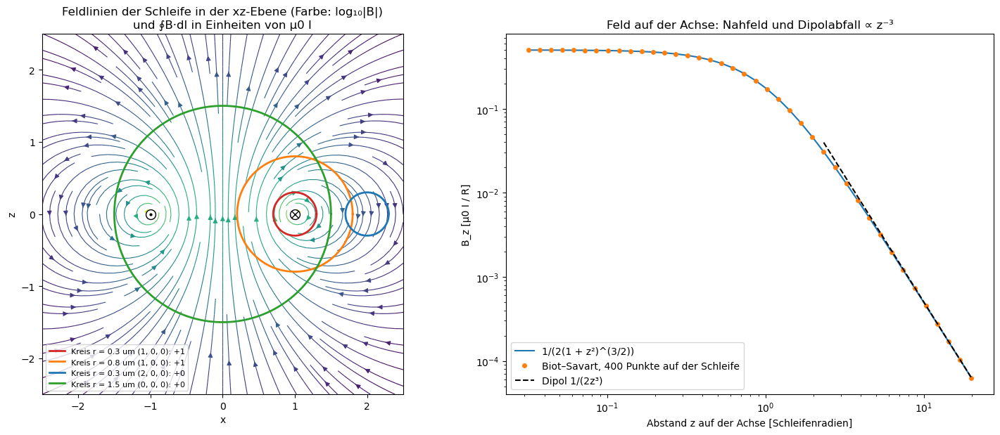

In [13]:
vectorcalc.magnetic_field()

**13. Wahrscheinlichkeitsstrom und quantisierte Wirbel**

Eine Wellenfunktion hat einen Wahrscheinlichkeitsstrom. Um eine Nullstelle dreht sich ihre Phase um ein Vielfaches von 2π: Die Zirkulation ist quantisiert.

Um die drei Nullstellen sind die Zirkulationen geteilt durch 2π genau +1, +1 und −1, auf neun Stellen; auf einem großen Kreis um alle drei ihre Summe +1. Solche Wirbel gibt es in Supraleitern und Superflüssigkeiten.

Kontinuitätsgleichung bei t = 0.7: max|∂ρ/∂t + div j| = 2.9e-04 bei max|∂ρ/∂t| = 0.41 (Gitter h = 0.02)
Nullstelle von ψ bei x + iy = −(a/b) e^(it): Radius a/b = 0.75, Umlaufzeit 2π
Zirkulation um z1            : ∮ v·dl / 2π = +1.000000000
Zirkulation um z2            : ∮ v·dl / 2π = +1.000000000
Zirkulation um z3 (z̄ − z̄3) : ∮ v·dl / 2π = -1.000000000
Zirkulation Kreis r = 2.5 um 0: ∮ v·dl / 2π = +1.000000000
Zirkulation um z1 und z3     : ∮ v·dl / 2π = +0.000000000


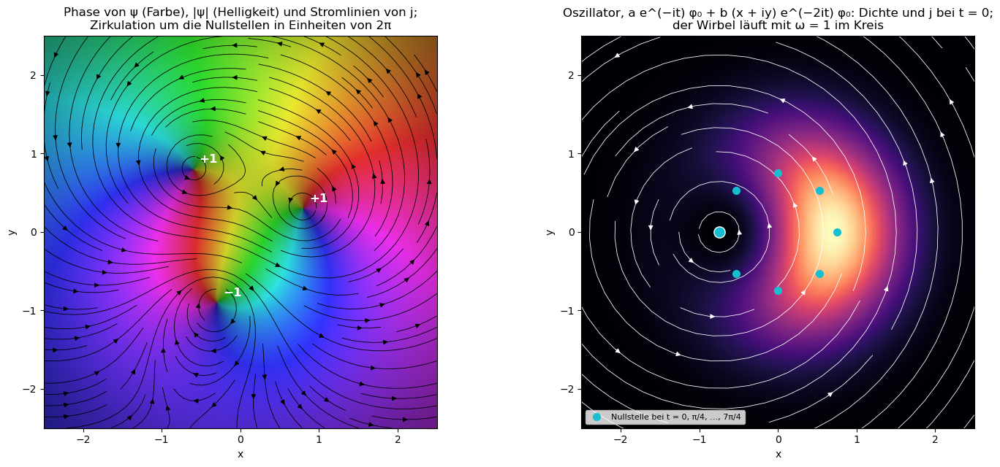

In [14]:
vectorcalc.probability_current()

**14. Berry-Krümmung: ein Monopol im Parameterraum**

Ein Spin ½ im Magnetfeld, dessen Richtung im Kreis geführt wird, sammelt eine geometrische Phase, die Berry-Phase: der halbe Raumwinkel des Kreises. Die zugehörige Berry-Krümmung ist das Feld eines Monopols.

Die Berry-Phase folgt π(1 − cos θ) auf 2.5·10⁻⁵ genau. Der Fluss der Berry-Krümmung durch die ganze Kugel ist 2π: eine ganze Zahl mal 2π, die Chern-Zahl, die in topologischen Materialien Leitwerte quantisiert.

Spin ½: Chern-Zahlen der Zustände (nach Energie aufsteigend): [ 1. -1.]
  unterer Zustand: Berry-Fluss / Raumwinkel pro Plakette = 0.499943 ± 1.2e-04 → Krümmung R̂/(2R²), ein Monopol der Stärke ½
Spin 1: Chern-Zahlen der Zustände (nach Energie aufsteigend): [ 2.  0. -2.]
Berry-Phase gegen Ω/2 (mod 2π): größte Abweichung 2.5e-05


QWZ, unteres Band: Chern-Zahl für m = −2.5, −1, 1, 2.5: [0.0, 1.0, -1.0, 0.0]


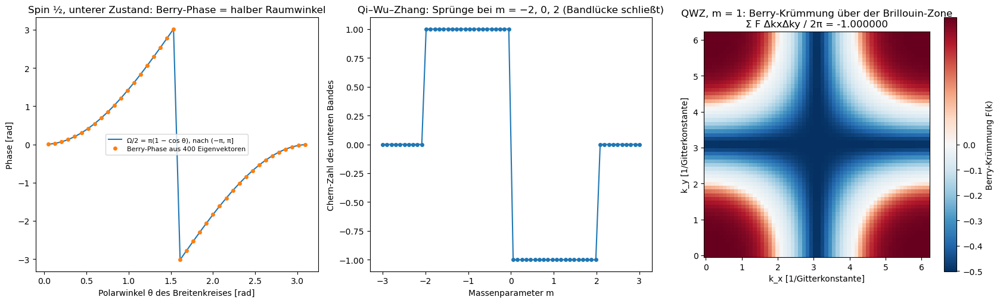

In [15]:
vectorcalc.berry_curvature()

**15. Tensoren: Werkzeuge**

Tensoranalysis beschreibt einen gekrümmten Raum von innen. Gauß zeigte 1827, dass sich die Krümmung einer Fläche allein mit Abständen auf der Fläche messen lässt; Riemann übertrug das 1854 auf beliebige Dimensionen, und Einstein beschrieb damit 1915 die Gravitation als Krümmung der Raumzeit. Bereitgestellt wird ein kleiner Werkzeugkasten mit sympy: Christoffel-Symbole, Riemann-, Ricci- und Einstein-Tensor aus einer beliebigen Metrik, dazu Geodäten und Paralleltransport.

Die Ausgabe meldet die Werkzeuge bereit.

In [16]:
tensors.load()

Werkzeuge bereit


**16. Die 2-Sphäre: Christoffel-Symbole und Krümmung**

Aus der Metrik der Kugel allein berechnet sympy die Christoffel-Symbole, den Riemann-Tensor, den Ricci-Tensor und den Ricci-Skalar.

Nur zwei Christoffel-Symbole sind von null verschieden. Der Riemann-Tensor hat eine einzige unabhängige Komponente, sin²θ, und der Ricci-Skalar ist 2/a²: Die Kugel ist überall gleich gekrümmt, umso stärker, je kleiner sie ist.

In [17]:
tensors.sphere()

Christoffel-Symbole Γ^a_bc:
  Γ[θ,φ,φ] = -sin(2*theta)/2
  Γ[φ,θ,φ] = 1/tan(theta)
  Γ[φ,φ,θ] = 1/tan(theta)
Riemann-Tensor R^a_bcd:
  R[θ,φ,θ,φ] = sin(theta)**2
  R[θ,φ,φ,θ] = -sin(theta)**2
  R[φ,θ,θ,φ] = -1
  R[φ,θ,φ,θ] = 1
Ricci-Tensor: [[1, 0], [0, sin(theta)**2]]
Ricci-Skalar R = 2/a**2,  Gauß-Krümmung K = R/2 = a**(-2)
Unabhängige Komponenten des Riemann-Tensors in n Dimensionen, n²(n²−1)/12: n=2: 1, n=3: 6, n=4: 20


**17. Geodäten auf der Sphäre**

Eine Geodäte startet auf dem Äquator nach Nordosten und wird numerisch integriert.

Sie ist ein Großkreis, um 45° gegen den Äquator geneigt, und erreicht 45° Nord und 45° Süd. Abstand von der Ebene durch den Mittelpunkt, Länge des Geschwindigkeitsvektors und Erhaltungsgröße bleiben auf Rundungsgenauigkeit konstant.

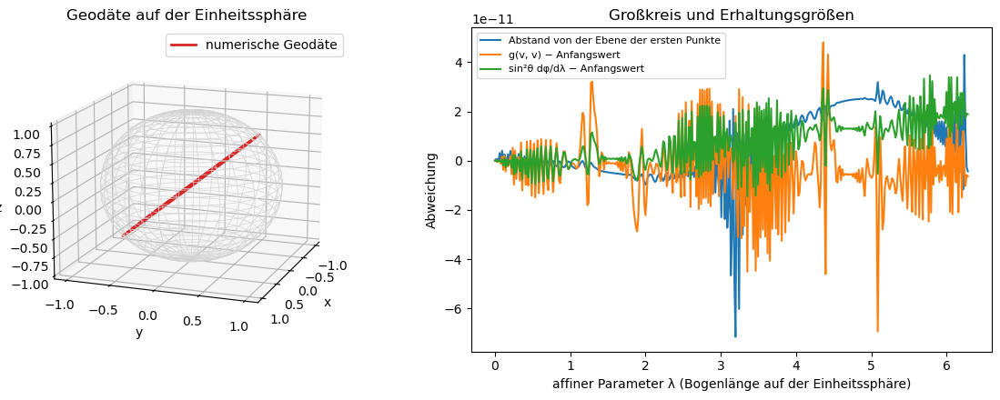

größter Abstand von der Großkreisebene: 7.1e-11
größte Drift von g(v,v): 6.9e-11,  von sin²θ φ': 3.5e-11


In [18]:
tensors.geodesics()

**18. Paralleltransport um einen Breitenkreis**

Ein Vektor wird um einen Breitenkreis parallel verschoben, ohne sich in der Fläche zu drehen. Am Ende ist er trotzdem um einen Winkel gedreht.

Der Drehwinkel ist die eingeschlossene Krümmung 2π(1 − cos θ₀), für alle 40 Kreise. Nahe dem Pol dreht sich der Vektor kaum, am Äquator um volle 360° und kommt unverändert zurück. So misst man Krümmung, ohne den Raum zu verlassen.

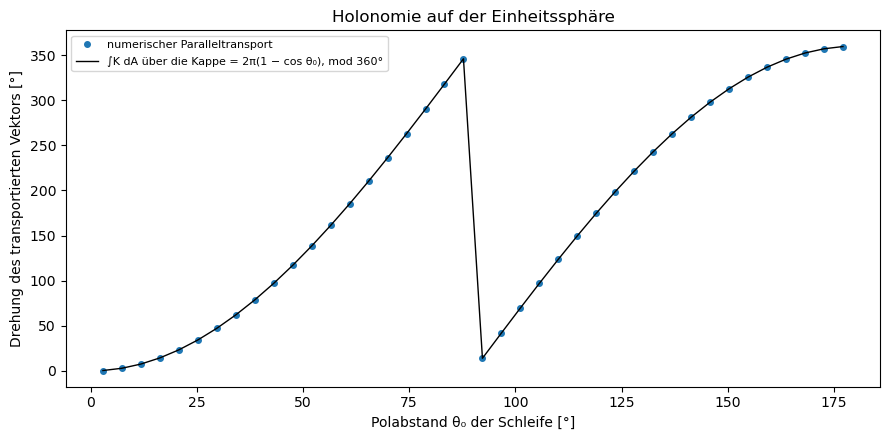

größte Abweichung von 2π(1 − cos θ₀) mod 2π: 1.85e-11 Grad
Beispiel θ₀ = 60°: Drehung 180.0000°, Kappenfläche/a² = 180.0000°


In [19]:
tensors.parallel_transport()

**19. Der Torus: Krümmung mit wechselndem Vorzeichen**

Die Krümmung des Torus, und die Probe des Satzes von Gauß-Bonnet: Das Integral der Krümmung über eine geschlossene Fläche ist 2π mal ihre Euler-Charakteristik.

Außen ist der Torus wie eine Kugel gekrümmt (positiv), innen um das Loch wie ein Sattel (negativ), oben und unten flach. Das Integral über den ganzen Torus ist null, wie Gauß-Bonnet für eine Fläche mit einem Loch verlangt.

Gauß-Krümmung des Torus: K = cos(theta)/(r*(R + r*cos(theta)))


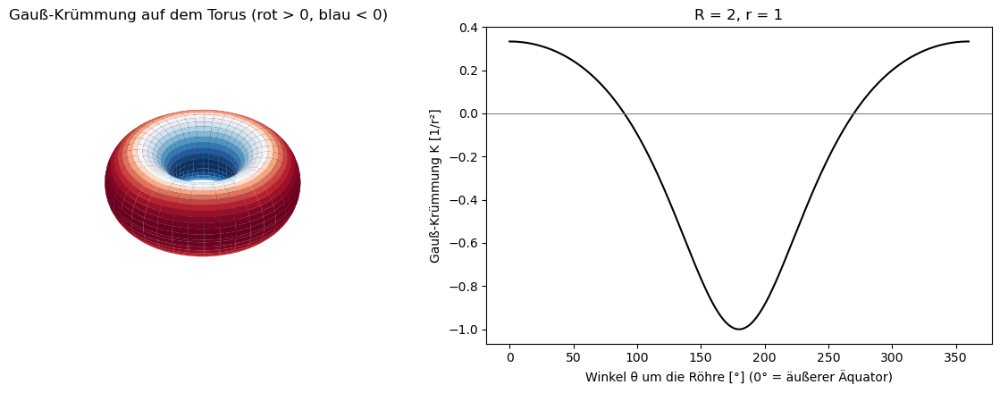

∫K dA, Torus:  -2.09e-15   (Gauß–Bonnet: 2π·χ = 0)
∫K dA, Sphäre: 12.566371   (Gauß–Bonnet: 2π·2 = 12.566371)


In [20]:
tensors.torus()

**20. Schwarzschild: Vakuum und Gezeitenkräfte**

Die Raumzeit um eine Masse M. Geprüft werden die Vakuumgleichung (Ricci-Tensor null), die erste Bianchi-Identität und der Kretschmann-Skalar; dazu die Gezeitenkräfte.

Der Ricci-Tensor verschwindet, die Bianchi-Identität gilt in allen 256 Komponenten. Der Kretschmann-Skalar 48M²/r⁶ ist am Horizont endlich: Der Horizont ist ein Artefakt der Koordinaten, die Singularität bei r = 0 ist echt. Die Gezeiten sind −2M/r³ radial: Am Horizont eines kleinen schwarzen Lochs wird man zerrissen, an dem eines großen kaum.

In [21]:
tensors.schwarzschild()

Ricci-Tensor von Schwarzschild: null (Vakuum)
Erste Bianchi-Identität: 0 verletzte Komponenten von 256
Kretschmann-Skalar: 48*M**2/r**6
R^r̂_t̂r̂t̂ = -2*M/r**3,   R^θ̂_t̂θ̂t̂ = M/r**3

Radiale Gezeitenbeschleunigung zwischen Kopf und Füßen (2 m):
  Erdoberfläche                          r = 6.371e+06 m:  Δa =  6.17e-06 m/s²
  Sonnenoberfläche                       r = 6.957e+08 m:  Δa =  1.58e-06 m/s²
  Horizont, 10 Sonnenmassen              r = 2.954e+04 m:  Δa =  2.06e+08 m/s²
  Horizont, Sgr A* (4,3e6 Sonnenmassen)  r = 1.270e+10 m:  Δa =  1.11e-03 m/s²


**21. Die kontrahierte Bianchi-Identität im expandierenden Universum**

Der Einstein-Tensor eines expandierenden Universums mit beliebigem Skalenfaktor a(t), und seine kovariante Divergenz.

Die Divergenz ist in allen vier Komponenten null, obwohl a(t) beliebig ist: eine Eigenschaft der Geometrie. Mit den Feldgleichungen folgen daraus die Friedmann-Gleichungen und die Erhaltung der Energie einer Flüssigkeit im expandierenden Raum.

In [22]:
tensors.bianchi()

Ricci-Skalar: R = 6*(a(t)*Derivative(a(t), (t, 2)) + Derivative(a(t), t)**2)/a(t)**2
G_tt = 3*Derivative(a(t), t)**2/a(t)**2,   G_xx = -2*a(t)*Derivative(a(t), (t, 2)) - Derivative(a(t), t)**2
∇_μ G^μν for ν = t, x, y, z: [0, 0, 0, 0]


**22. Geodäten um die Sonne**

Lichtstrahlen und Planetenbahnen als Geodäten der Schwarzschild-Raumzeit: Ablenkung des Lichts und Drehung des Perihels.

Die Ablenkung folgt 4M/b über vier Dekaden, die Periheldrehung 6πM/p. Für die Sonne ergibt das 1.75″ für einen streifenden Lichtstrahl, wie Eddington 1919 maß, und 43″ pro Jahrhundert für das Perihel des Merkur.

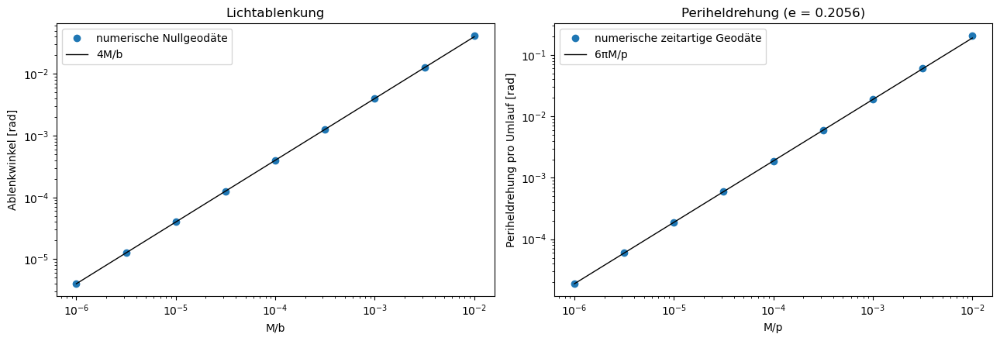

Licht am Sonnenrand: 1.7512″   (4GM/(c²R) = 1.7512″)
Merkur: 5.0185e-07 rad pro Umlauf = 42.98″ pro Jahrhundert   (6πGM/(c²a(1−e²)) = 42.98″)


In [23]:
tensors.light_bending()

**23. Projektive Geometrie: Fluchtpunkte und Horizont**

Ein Maler lässt die parallelen Ränder einer Straße am Horizont in einem Punkt zusammenlaufen. Die projektive Geometrie nimmt das ernst: Sie fügt für jede Richtung einen Punkt im Unendlichen hinzu, und diese Punkte bilden den Horizont. Danach schneiden sich zwei Geraden immer in genau einem Punkt, und die Rechnung wird linear. Eine Kamera blickt auf einen Boden mit parallelen Linien.

Die Linien in Blickrichtung laufen in einem Fluchtpunkt zusammen, die Diagonalen in zwei weiteren, alle auf dem Horizont. Querlinien bleiben parallel: Ihr Fluchtpunkt liegt im Unendlichen des Bildes.

Fluchtpunkt vorwärts (0, 0, 1)    : (   640.0,  247.6) px, liegt auf dem Horizont: True
Fluchtpunkt diagonal (1, 0, 1)    : (  1447.9,  247.6) px, liegt auf dem Horizont: True
Fluchtpunkt diagonal (−1, 0, 1)   : (  -167.9,  247.6) px, liegt auf dem Horizont: True


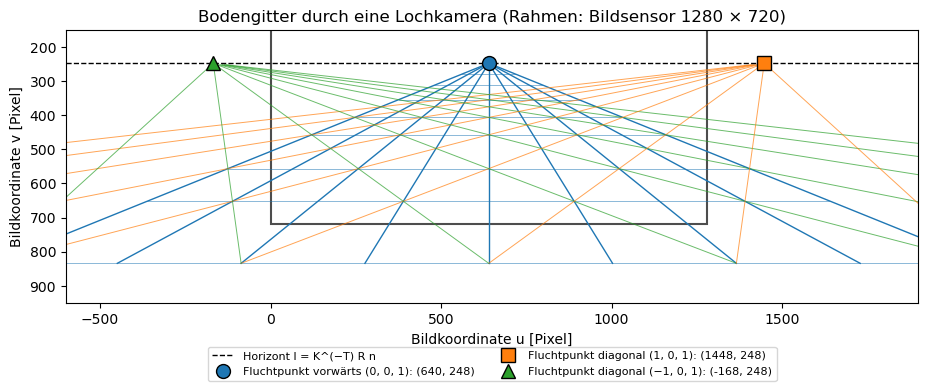

In [24]:
projective.perspective()

**24. Homogene Koordinaten**

Ein Punkt der Ebene wird ein Vektor (x : y : w), eine Gerade ebenso. Verbindung und Schnitt sind dann Kreuzprodukte, und Punkte mit w = 0 liegen im Unendlichen.

Parallele Geraden schneiden sich in einem Punkt mit w = 0, dem gemeinsamen Punkt im Unendlichen in ihrer Richtung. Die projektive Ebene ist die Menge der Geraden durch den Ursprung im Raum; die Ebene w = 1 ist nur eine Karte davon.

l1 × l2 = [6. 3. 0.] -> w = 0: Punkt im Unendlichen in Richtung [0.89442719 0.4472136 ]
liegt auf der Geraden im Unendlichen (0, 0, 1): True
l1 × l3 = [7. 6. 5.] -> affin [1.4 1.2]
Verbindungsgerade der beiden Schnittpunkte auf l3: [ 2.  1. -4.] = l3 bis auf einen Faktor: True
Kollinearität |det| von zwei Schnittpunkten und (1, 2): 1.4e-17


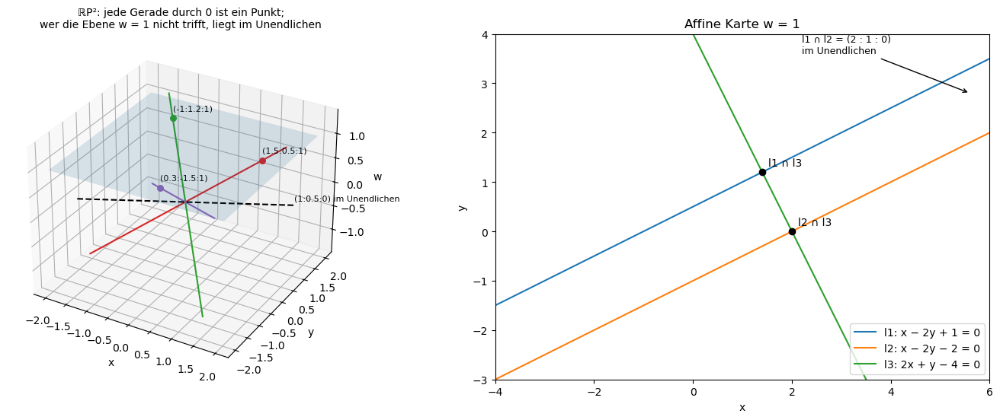

In [25]:
projective.homogeneous()

**25. Die Hierarchie der Transformationen**

Euklidische Abbildungen, Ähnlichkeiten, affine und projektive Abbildungen, angewendet auf ein Gitter mit einem Kreis.

Euklidische Abbildungen erhalten Längen, Ähnlichkeiten Winkel, affine Abbildungen Parallelität: Das Gitter wird zu Parallelogrammen, der Kreis zur Ellipse. Projektive Abbildungen erhalten nur Geraden und das Doppelverhältnis; die Gitterlinien laufen aufeinander zu.

projektive Matrix bildet die vier Ecken richtig ab: True

               Länge   Winkel  parallel  Teilverh.  Doppelverh.
Original       1.000    90.00        ja      0.500       1.5000
euklidisch     1.000    90.00        ja      0.500       1.5000
Ähnlichkeit    1.500    90.00        ja      0.500       1.5000
affin          1.204    48.37        ja      0.500       1.5000
projektiv      1.612    68.84      nein      0.478       1.5000


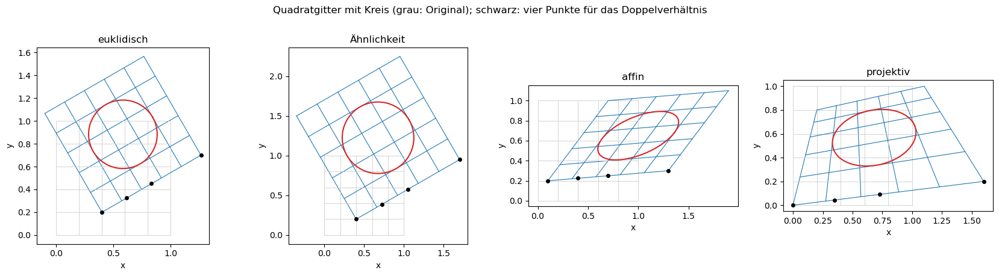

In [26]:
projective.transformations()

**26. Das Doppelverhältnis und die Möbius-Abbildungen**

Unter projektiven Abbildungen ändern sich Abstände und Verhältnisse, das Doppelverhältnis von vier Punkten auf einer Geraden bleibt. Möbius-Abbildungen sind die projektiven Abbildungen der komplexen Ebene.

Unter 2000 zufälligen Abbildungen streut das einfache Teilverhältnis breit, das Doppelverhältnis ist jedes Mal 1.125000. Möbius-Abbildungen machen aus Geraden Kreise und erhalten das Doppelverhältnis komplexer Zahlen; vier Punkte auf einem Kreis bleiben auf einem Kreis.

Doppelverhältnis vorher 1.125000, nachher 1.125000 bis 1.125000
Teilverhältnis AC/BC vorher 1.500, nachher Median 2.649, Bereich 1.25 bis 18.36 (5 %- bis 95 %-Perzentil)
Die sechs Werte unter den 24 Vertauschungen: [-8.0, -0.125, 0.1111, 0.8889, 1.125, 9.0]
λ, 1/λ, 1−λ, 1/(1−λ), λ/(λ−1), (λ−1)/λ: [-8.     -0.125   0.1111  0.8889  1.125   9.    ]

Doppelverhältnis von vier Punkten eines Kreises: 1.6884+0.0000j (reell), nach der Möbius-Abbildung: 1.6884+0.0000j


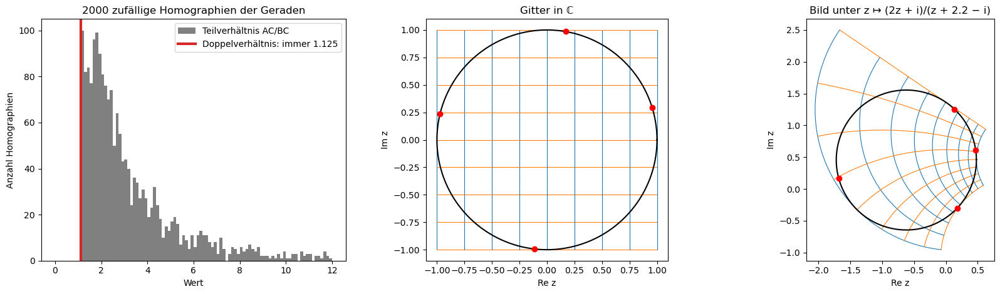

In [27]:
projective.cross_ratio()

**27. Desargues, Pappus, Pascal und Brianchon**

Vier klassische Sätze, in denen Punkte auf einer Geraden liegen oder Geraden durch einen Punkt gehen, numerisch geprüft.

Desargues: Sind zwei Dreiecke perspektiv zu einem Punkt, liegen die Schnittpunkte ihrer Seiten auf einer Geraden. Pappus: Drei Punktepaare über Kreuz verbunden geben drei Punkte auf einer Geraden. Pascal: Die gegenüberliegenden Seiten eines Sechsecks in einem Kegelschnitt schneiden sich auf einer Geraden; Brianchon ist der duale Satz.

Desargues : |det| über 2000 zufällige Konfigurationen höchstens 1.9e-12


Pappus    : |det| über 2000 zufällige Konfigurationen höchstens 1.4e-15


Pascal    : |det| über 2000 zufällige Konfigurationen höchstens 2.4e-12


Brianchon : |det| über 2000 zufällige Konfigurationen höchstens 3.8e-12


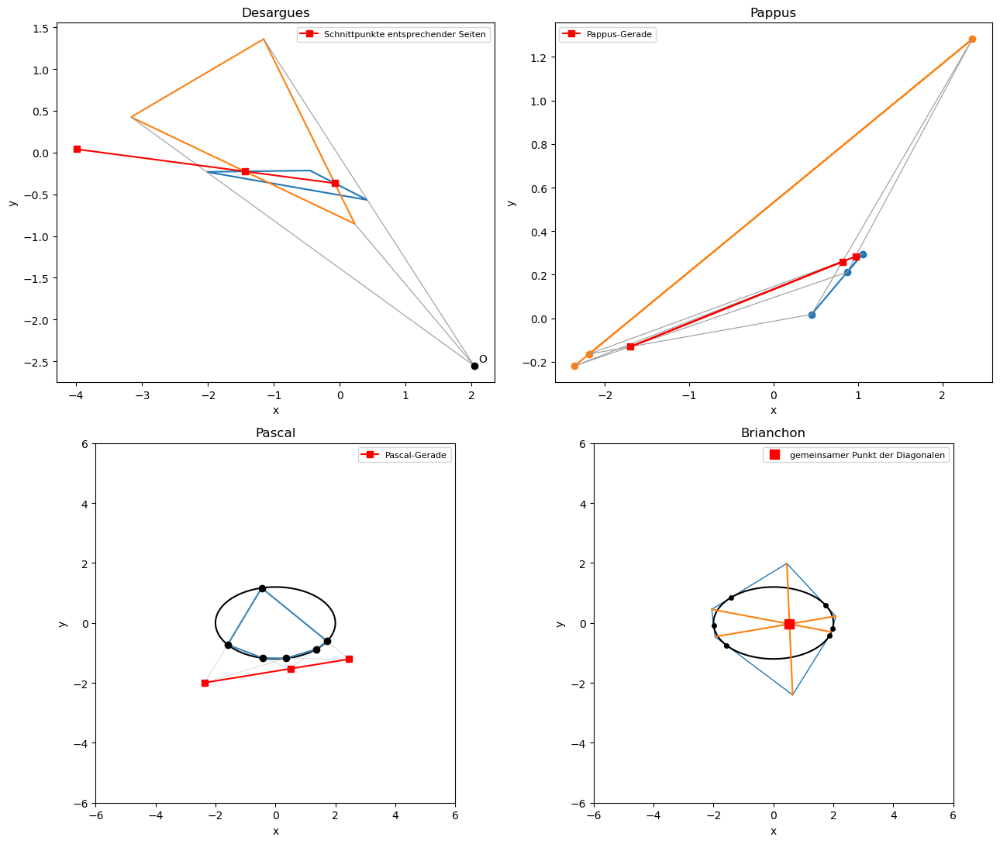

In [28]:
projective.classical_theorems()

**28. Kegelschnitte: eine Kurve, drei Gesichter**

Projektiv sind Ellipse, Parabel und Hyperbel dieselbe Kurve; sie unterscheiden sich nur darin, wie sie die Gerade im Unendlichen treffen. Ein Kreis wird so abgebildet, dass eine von drei Geraden ins Unendliche geht.

Trifft die Gerade den Kreis nicht, entsteht eine Ellipse, berührt sie ihn, eine Parabel, schneidet sie ihn zweimal, eine Hyperbel mit zwei Ästen. Dazu die Polare eines Punktes, die durch die beiden Berührpunkte seiner Tangenten geht.

a = 0.5: Typ Ellipse , Determinante des 2×2-Blocks +0.750
a = 1: Typ Parabel , Determinante des 2×2-Blocks +0.000
a = 2: Typ Hyperbel, Determinante des 2×2-Blocks -3.000


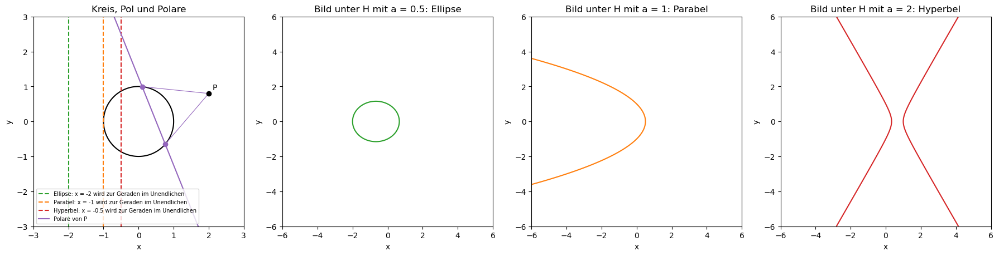

Kreis um (+2.14, +0.21), Radius 1.01: Iᵀ C I = 0.0e+00+0.0e+00j
Kreis um (+1.66, +0.22), Radius 1.83: Iᵀ C I = 0.0e+00+0.0e+00j
Kreis um (-1.22, -0.54), Radius 0.87: Iᵀ C I = 0.0e+00+0.0e+00j
Ellipse x²/4 + y² = 1: Iᵀ C I = -0.75+0.00j (kein Kreis)


In [29]:
projective.conics()

**29. Cayley-Klein: hyperbolische Geometrie im Kreis**

Im Inneren eines Kreises wird ein Abstand über das Doppelverhältnis definiert; die Geraden sind Sehnen. Das ergibt die hyperbolische Geometrie, in der es zu einer Geraden durch einen Punkt viele Parallelen gibt.

Kreise mit demselben hyperbolischen Radius werden zum Rand hin immer kleiner; der Rand ist unendlich weit weg. Der Abstand ist entlang einer Geraden additiv und bleibt unter hyperbolischen Drehungen (Boosts) gleich, während sich der euklidische Abstand ändert: So rechnet auch die Relativitätstheorie mit Geschwindigkeiten.

Additivität: d(p,q) + d(q,r) = 0.941501, d(p,r) = 0.941501
d(0, ρ) gegen artanh ρ: 1.472219 gegen 1.472219
Boost: hyperbolisch 0.75057 -> 0.75057, euklidisch 0.5450 -> 0.2212
Boost: hyperbolisch 0.15139 -> 0.15139, euklidisch 0.1033 -> 0.1183
Boost: hyperbolisch 0.67968 -> 0.67968, euklidisch 0.4893 -> 0.5298


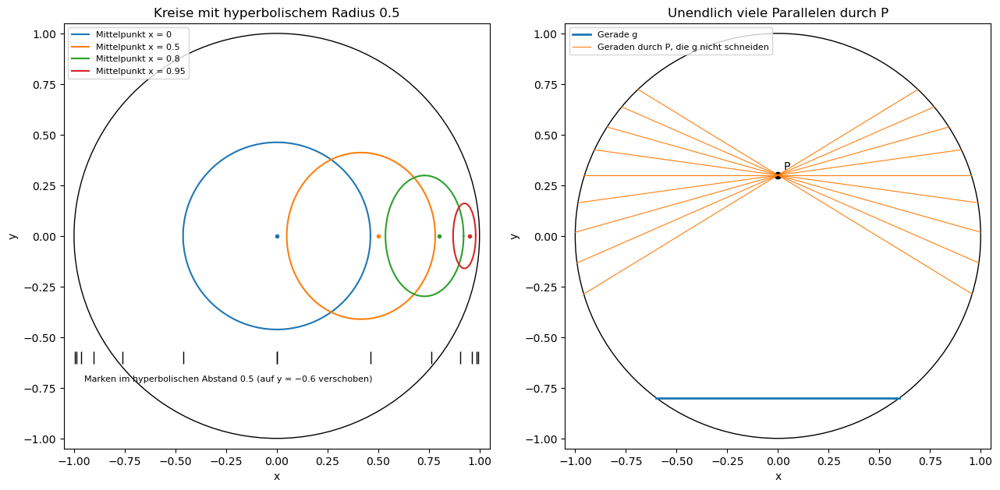

In [30]:
projective.cayley_klein()

**30. Computer Vision: Homographie schätzen und entzerren**

Ein perspektivisch fotografiertes Schachbrett wird entzerrt. Vier Punktpaare bestimmen die Homographie exakt; mit Rauschen schätzt man sie aus vielen Punkten (DLT).

Das entzerrte Brett hat quadratische Felder von 100 mm. Der Übertragungsfehler wächst proportional zum Rauschen. Normierte Koordinaten machen das Gleichungssystem viel besser konditioniert (3 gegen 16 000); der Fehler ist hier fast gleich, bei größeren Bildern oder einfacher Genauigkeit zählt das aber. So rechnen Panoramas, Dokumentenscanner und Fahrerassistenz.

DLT mit Normierung  : Konditionszahl  3.20e+00, mittlerer Übertragungsfehler [0.056 0.165 0.541 1.628 5.665] px für σ = [ 0.1  0.3  1.   3.  10. ]
DLT ohne Normierung : Konditionszahl  1.58e+04, mittlerer Übertragungsfehler [0.055 0.159 0.539 1.628 5.818] px für σ = [ 0.1  0.3  1.   3.  10. ]


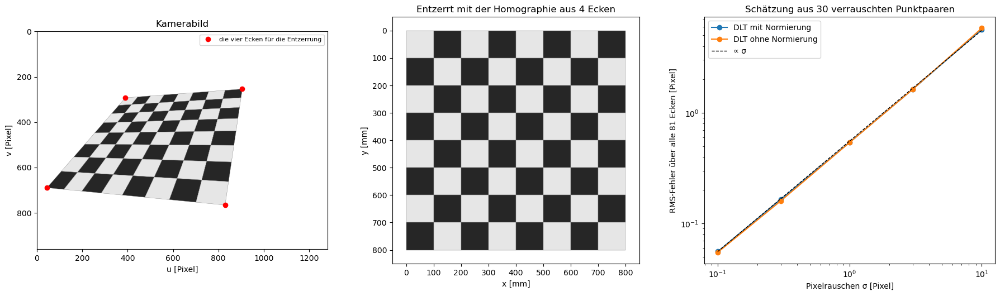

In [31]:
projective.homography()

**31. Endliche projektive Ebenen**

Über einem endlichen Körper hat die projektive Ebene endlich viele Punkte. Die kleinste ist die Fano-Ebene mit sieben Punkten und sieben Geraden.

In der Fano-Ebene liegen auf jeder Geraden drei Punkte, und je zwei Geraden schneiden sich in genau einem Punkt; eine der Geraden muss man als Kreis zeichnen. Über 𝔽_q hat die Ebene q² + q + 1 Punkte (13, 31, 57 für q = 3, 5, 7). Aus der Fano-Ebene entsteht der Hamming-Code [7, 4, 3], der einen Fehler korrigiert.

q = 2:   7 Punkte (q²+q+1 = 7), Punkte pro Gerade [3], N Nᵀ = qI + J: True
q = 3:  13 Punkte (q²+q+1 = 13), Punkte pro Gerade [4], N Nᵀ = qI + J: True
q = 5:  31 Punkte (q²+q+1 = 31), Punkte pro Gerade [6], N Nᵀ = qI + J: True
q = 7:  57 Punkte (q²+q+1 = 57), Punkte pro Gerade [8], N Nᵀ = qI + J: True

Fano-Code: 16 Codewörter, linear: True, Mindestabstand 3 -> der [7, 4, 3]-Hamming-Code


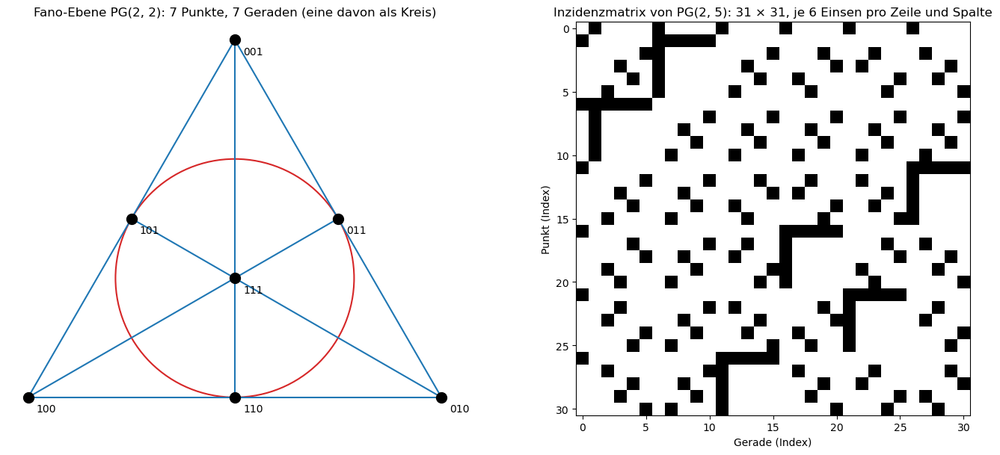

In [32]:
projective.finite_planes()

**32. Die projektive Gerade über 𝔽_p**

Die Geraden durch den Ursprung von 𝔽₅² sind die p + 1 = 6 Punkte der projektiven Geraden. Daraus entstehen sechs Basen eines Quantensystems mit fünf Zuständen, die gegenseitig unverzerrt sind.

Jede Basis ist orthonormal, und jeder Zustand einer Basis überlappt mit jedem einer anderen gleich stark, mit 1/5. Solche Basen sind optimal für Tomographie und Quantenkryptographie, und es gibt d + 1 davon, wenn d eine Primzahlpotenz ist.

Punkte von PG(1, 5) = Geraden durch 0 in F_5²:
  (0 : 1): [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4)]
  (1 : 0): [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0)]
  (1 : 1): [(0, 0), (1, 1), (2, 2), (3, 3), (4, 4)]
  (1 : 2): [(0, 0), (1, 2), (2, 4), (3, 1), (4, 3)]
  (1 : 3): [(0, 0), (1, 3), (2, 1), (3, 4), (4, 2)]
  (1 : 4): [(0, 0), (1, 4), (2, 3), (3, 2), (4, 1)]
jeder der 24 Vektoren ≠ 0 liegt auf genau einer Geraden: True
innerhalb einer Basis: größte Abweichung von δ 8.9e-16; zwischen Basen: größte Abweichung von 1/p 6.7e-16


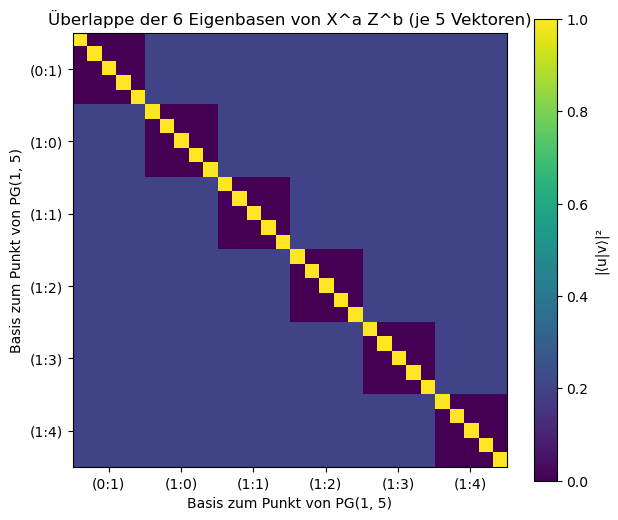

In [33]:
projective.projective_line()

**33. Die Bloch-Kugel als Riemann-Kugel**

Die Zustände eines Qubits sind die Punkte der komplexen projektiven Geraden ℂP¹, und die ist eine Kugel: die Bloch-Kugel. Die stereographische Projektion macht daraus die komplexe Ebene mit einem Punkt im Unendlichen.

|0⟩ geht nach 0, |+⟩ und |+i⟩ auf den Einheitskreis, |1⟩ nach unendlich. Breitenkreise werden zu Kreisen um 0, Längenkreise zu Strahlen; Drehungen der Kugel werden Möbius-Abbildungen.

globale Phase ändert z nicht: True | Bloch-Vektor über z und direkt gleich: True


200 zufällige Unitäre: Möbius-Abbildung von z = Drehung R ∈ SO(3) des Bloch-Vektors, größte Abweichung 5.2e-15


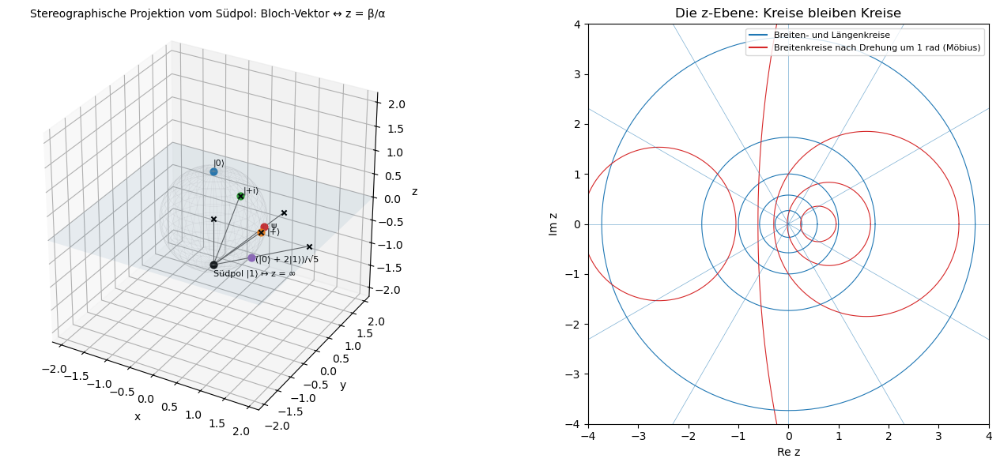

In [34]:
projective.bloch_riemann()

**34. Fubini-Study-Metrik und Haar-Zustände**

Der natürliche Abstand zwischen Quantenzuständen ist der Fubini-Study-Abstand, arccos |⟨ψ|φ⟩|. Für ein Qubit ist er der halbe Winkel auf der Bloch-Kugel.

500 Paare liegen genau auf dieser Beziehung, orthogonale Zustände haben den Abstand π/2. Zufällige Zustände (Haar-Maß) sind auf der Bloch-Kugel gleichverteilt; in höheren Dimensionen ist ihr Überlapp fast immer klein, die Zustände stehen fast senkrecht aufeinander.

Qubits: größte Abweichung d_FS − (Winkel/2) = 3.5e-15
N = 6: 4 Var(G) = 34.571831, 4 (d_FS/δ)² = 34.571831


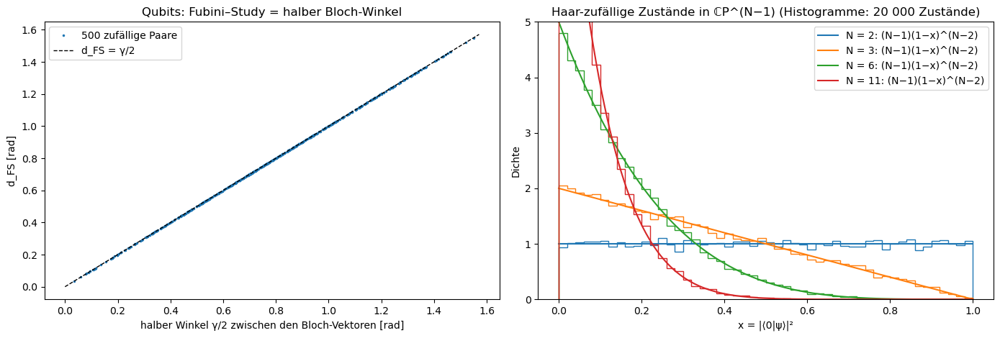

In [35]:
projective.fubini_study()

**35. Geometrische Phase und Hopf-Faserung**

Läuft ein Zustand auf der Bloch-Kugel einen geschlossenen Weg, sammelt er eine Phase gleich dem halben eingeschlossenen Raumwinkel. Dahinter steht die Hopf-Faserung: Jeder Punkt der Bloch-Kugel ist ein Kreis von Phasen in der 3-Sphäre.

Für 1000 zufällige Dreiecke ist die geometrische Phase genau der halbe Raumwinkel, auf 10⁻¹⁴, egal welche Phasen die Vektoren haben. Die Fasern zweier Breitenkreise bilden in die Ebene projiziert verschlungene Ringe, die Hopf-Ringe.

arg(Bargmann) − Ω/2: größte Abweichung 1.0e-14 (geometrische Phase des Umlaufs 1→2→3→1: γ = −Ω/2)


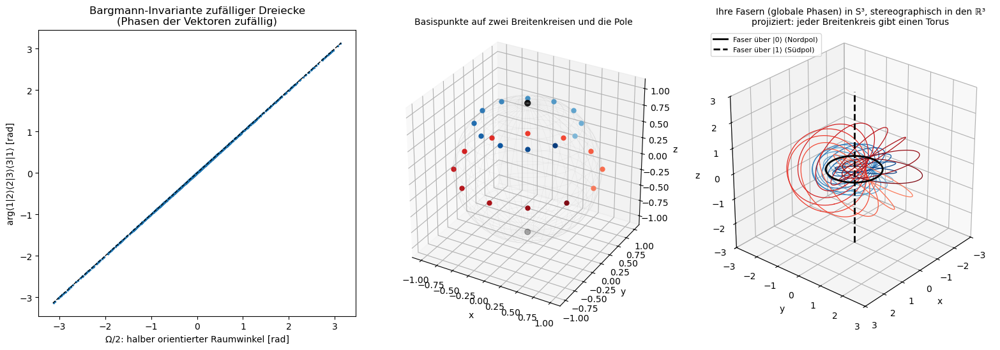

Gauß-Verschlingungszahl zweier Fasern: +1.000


In [36]:
projective.hopf()

**36. Segre und Veronese: Verschränkung und Majorana-Sterne**

Produktzustände zweier Qubits bilden eine Fläche im Zustandsraum, die Segre-Varietät; ihr Abstand misst die Verschränkung. Symmetrische Zustände vieler Qubits zerfallen in Punkte auf der Kugel, die Majorana-Sterne.

Der Abstand zu den Produktzuständen hängt nur von der Concurrence ab, von 0 bis π/4 beim Bell-Zustand. Ein kohärenter Zustand hat alle Majorana-Sterne an einer Stelle, der Dicke-Zustand mit zwei Anregungen je zwei an den Polen, ein zufälliger symmetrischer Zustand verteilt sie über die Kugel.

Produktzustand: c00 c11 − c01 c10 = 1.6e-17
größte Abweichung von arccos √((1 + √(1−C²))/2): 5.0e-14
kohärent, n = 4             : Sterne (x, y, z) = [[0.74, 0.4, 0.54], [0.74, 0.4, 0.54], [0.74, 0.4, 0.54], [0.74, 0.4, 0.54]]
GHZ, n = 5                  : Sterne (x, y, z) = [[1.0, 0.0, -0.0], [0.31, 0.95, 0.0], [0.31, -0.95, 0.0], [-0.81, 0.59, -0.0], [-0.81, -0.59, 0.0]]
Dicke |D_2⟩, n = 4          : Sterne (x, y, z) = [[0.0, 0.0, 1.0], [0.0, 0.0, 1.0], [0.0, 0.0, -1.0], [0.0, 0.0, -1.0]]


zufällig symmetrisch, n = 6 : Sterne (x, y, z) = [[-0.32, -0.12, 0.94], [-0.28, 0.91, 0.31], [0.95, -0.29, 0.11], [0.34, -0.94, -0.08], [-0.75, -0.46, -0.47], [-0.39, 0.11, -0.91]]
Bloch-Vektor des kohärenten Zustands: [0.74, 0.4, 0.54]


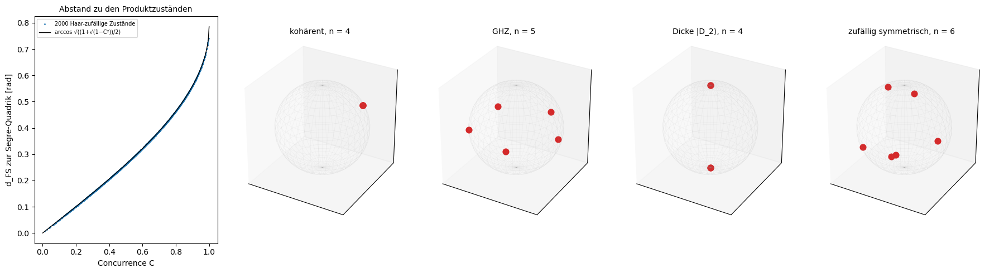

In [37]:
projective.segre_veronese()

**37. Quadriken und elliptische Kurven: Werkzeuge**

Gleichungen vom Grad 2 beschreiben Kegelschnitte und Quadrikflächen: Apollonios gab Ellipse, Parabel und Hyperbel ihre Namen, Kepler fand die Planeten auf Ellipsen. Heute legen Eigenwerte und Signatur einer symmetrischen Matrix den Typ fest. Eine Stufe höher, beim Grad 3, stehen die elliptischen Kurven: Ihre Punkte bilden eine Gruppe, auf der die Kryptographie im Internet beruht. Bereitgestellt werden Invarianten und Hauptachsen von Kegelschnitten und die Gruppenaddition auf elliptischen Kurven über ℚ, ℝ und endlichen Körpern.

Die Ausgabe meldet die Werkzeuge bereit.

In [38]:
quadrics.load()

Werkzeuge bereit


**38. Kegelschnitte: Invarianten und Hauptachsen**

Vier gedrehte und verschobene Kegelschnitte. Aus zwei Determinanten folgt der Typ, aus den Eigenvektoren die Hauptachsen.

Ellipse, Hyperbel, Parabel und Geradenpaar werden aus den Invarianten richtig erkannt; die Determinante des quadratischen Teils ist positiv, negativ oder null. Die Hauptachsen sind die Symmetrieachsen; die lange Achse der Ellipse zeigt in Richtung des kleineren Eigenwerts.

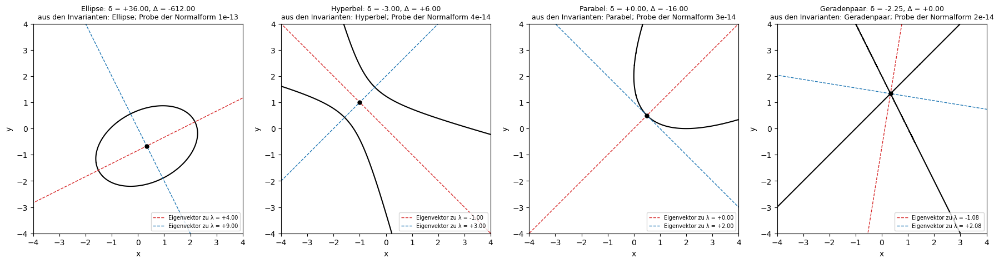

Ellipse     : Normalform +4.000 u² +9.000 v² -17.000 = 0;  Zentrum (0.333, -0.667), Halbachsen 2.062 und 1.374
Hyperbel    : Normalform -1.000 u² +3.000 v² -2.000 = 0;  Zentrum (-1.000, 1.000), Halbachsen 1.414 und 0.816
Parabel     : Normalform +2.000 w₂² +5.657 w₁ = 0, also w₂² = -2.828 w₁;  Scheitel (0.500, 0.500)
Geradenpaar : Normalform -1.081 u² +2.081 v² = 0 (Konstante 0e+00), also v = ±0.721 u;  Schnittpunkt (0.333, 1.333), Winkel zwischen den Geraden 71.57°


In [39]:
quadrics.conic_invariants()

**39. Der Kegel, die Exzentrizität und die Keplerbahnen**

Ebenen schneiden einen Kegel in Ellipse, Parabel und Hyperbel; dazu Bahnen um einen Zentralkörper mit wachsender Startgeschwindigkeit.

Je steiler die Ebene, desto größer die Exzentrizität: unter 1 die Ellipse, gleich 1 die Parabel, darüber die Hyperbel. Die Bahnen haben genau die Exzentrizität, die der Laplace-Runge-Lenz-Vektor vorhersagt (0.5, 1.0, 1.6), und dieser Vektor bleibt bis auf 10⁻¹¹ konstant.

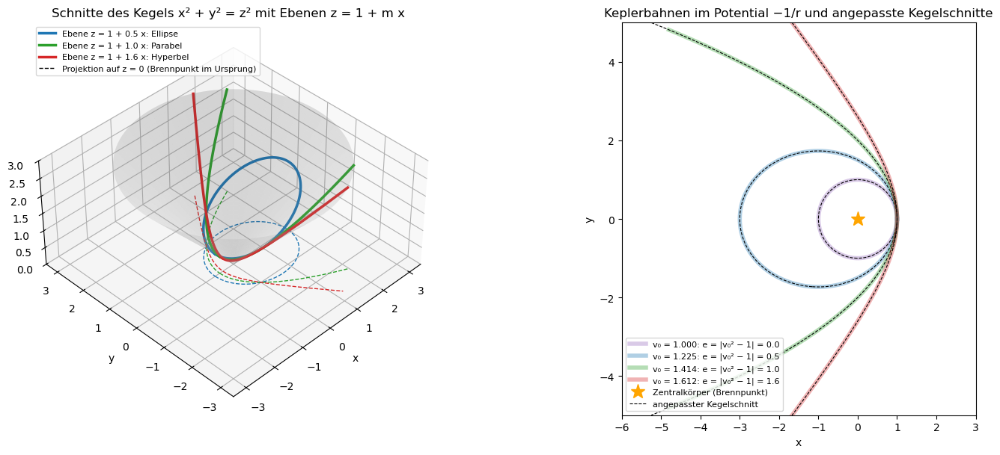

Kegelschnitt mit m = 0.5: Exzentrizität aus der Anpassung 0.5000000000, Typ Ellipse
Kegelschnitt mit m = 1.0: Exzentrizität aus der Anpassung 1.0000000000, Typ Parabel
Kegelschnitt mit m = 1.6: Exzentrizität aus der Anpassung 1.6000000000, Typ Hyperbel
Bahn v₀ = 1.0000: e Theorie 0.000, |A| = 0.0000000000, Drift von A 2e-12, e aus der Anpassung 0.00000017 (Ellipse), Residuum σ_min/σ_max = 9e-13
Bahn v₀ = 1.2247: e Theorie 0.500, |A| = 0.5000000000, Drift von A 6e-11, e aus der Anpassung 0.50000000 (Ellipse), Residuum σ_min/σ_max = 1e-12
Bahn v₀ = 1.4142: e Theorie 1.000, |A| = 1.0000000000, Drift von A 2e-11, e aus der Anpassung 1.00000000 (Parabel), Residuum σ_min/σ_max = 1e-13
Bahn v₀ = 1.6125: e Theorie 1.600, |A| = 1.6000000000, Drift von A 2e-11, e aus der Anpassung 1.60000000 (Hyperbel), Residuum σ_min/σ_max = 6e-14


In [40]:
quadrics.cone_eccentricity()

**40. Quadrikflächen**

Sechs Flächen vom Grad 2 im Raum mit ihrer Signatur, und die Geraden, die auf manchen von ihnen liegen.

Ellipsoid, zweischaliges Hyperboloid und elliptisches Paraboloid haben dieselbe Signatur: Projektiv sind sie alle eine Kugel. Das einschalige Hyperboloid und der Sattel enthalten durch jeden Punkt zwei Geraden; deshalb baut man Kühltürme aus geraden Stäben.

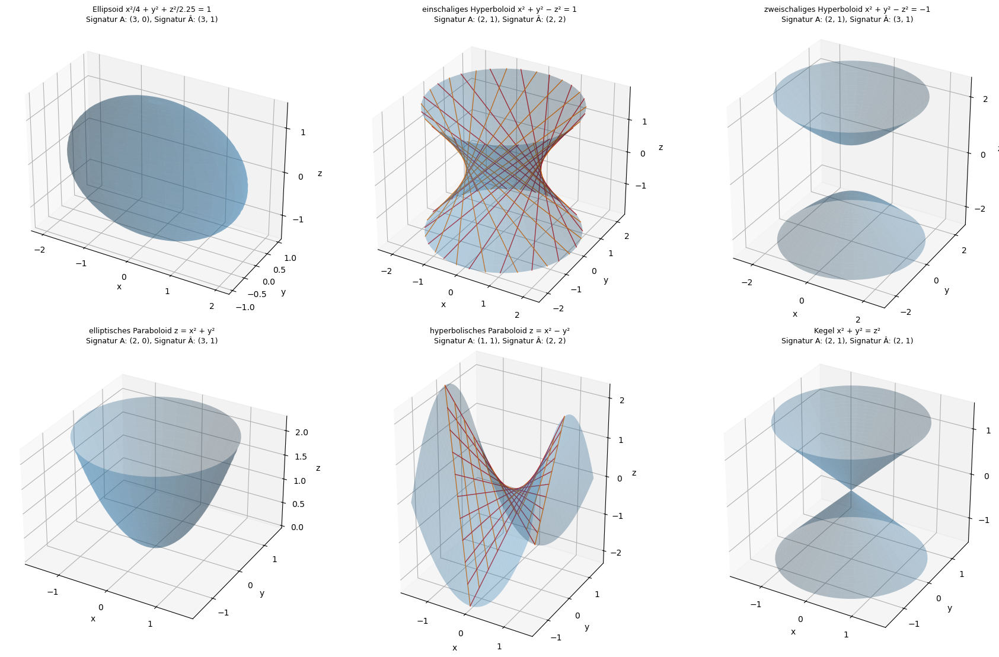

Ellipsoid x²/4 + y² + z²/2.25 = 1              Signatur Â = (3, 1): nicht geregelt, projektiv eine Kugel
einschaliges Hyperboloid x² + y² − z² = 1      Signatur Â = (2, 2): doppelt geregelt
zweischaliges Hyperboloid x² + y² − z² = −1    Signatur Â = (3, 1): nicht geregelt, projektiv eine Kugel
elliptisches Paraboloid z = x² + y²            Signatur Â = (3, 1): nicht geregelt, projektiv eine Kugel
hyperbolisches Paraboloid z = x² − y²          Signatur Â = (2, 2): doppelt geregelt
Kegel x² + y² = z²                             Signatur Â = (2, 1): Rang 3, Kegel (entartet)
Probe der Geraden: größte |F| auf dem Hyperboloid 1.8e-15, auf dem Sattel 4.4e-16


In [41]:
quadrics.quadric_surfaces()

**41. Quadratische Formen in Optimierung und Statistik**

Eine quadratische Form ist eine Schüssel; das Verhältnis κ ihrer größten zur kleinsten Krümmung bestimmt, wie schwer das Minimum zu finden ist. In der Statistik ist die Kovarianzmatrix eine solche Form.

Das Gradientenverfahren zieht sich pro Schritt um (κ − 1)/(κ + 1) zusammen, wie gemessen: bei κ = 10 braucht es 69 Schritte für einen Faktor 10⁻⁶, bei κ = 50 schon 345. Der Anteil einer zweidimensionalen Normalverteilung in der Ellipse vom Mahalanobis-Radius r ist 1 − e^(−r²/2).

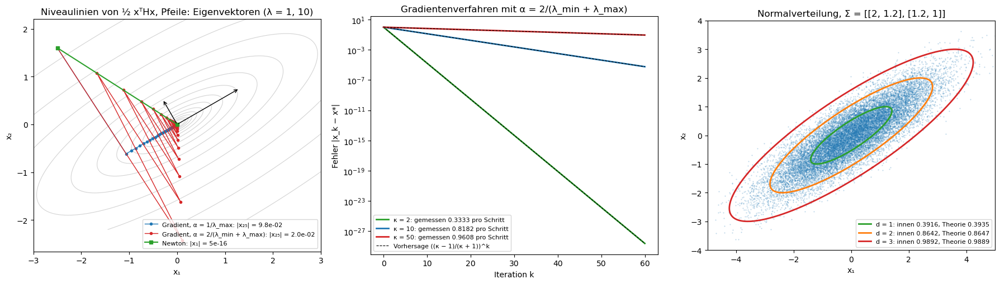

κ =  2: Kontraktion pro Schritt gemessen 0.333333, Theorie (κ − 1)/(κ + 1) = 0.333333; Schritte für Faktor 10⁻⁶: 13
κ = 10: Kontraktion pro Schritt gemessen 0.818182, Theorie (κ − 1)/(κ + 1) = 0.818182; Schritte für Faktor 10⁻⁶: 69
κ = 50: Kontraktion pro Schritt gemessen 0.960784, Theorie (κ − 1)/(κ + 1) = 0.960784; Schritte für Faktor 10⁻⁶: 345
Anteil in der Ellipse d ≤ 1: 0.3916 (Theorie 1 − e^(−r²/2) = 0.3935)
Anteil in der Ellipse d ≤ 2: 0.8642 (Theorie 1 − e^(−r²/2) = 0.8647)
Anteil in der Ellipse d ≤ 3: 0.9892 (Theorie 1 − e^(−r²/2) = 0.9889)


In [42]:
quadrics.quadratic_forms()

**42. Rationale Punkte auf Kegelschnitten**

Geraden mit rationaler Steigung durch einen rationalen Punkt des Einheitskreises treffen ihn ein zweites Mal in einem rationalen Punkt. Daraus entstehen alle pythagoreischen Tripel.

Die Steigung ½ ergibt (3/5, 4/5), das Tripel (3, 4, 5). Die rationalen Punkte liegen dicht auf dem Kreis. Ob x² + y² = n überhaupt rationale Lösungen hat, entscheidet die Zahlentheorie: für 10 und 13 ja, für 11, 12, 14, 15 nicht.

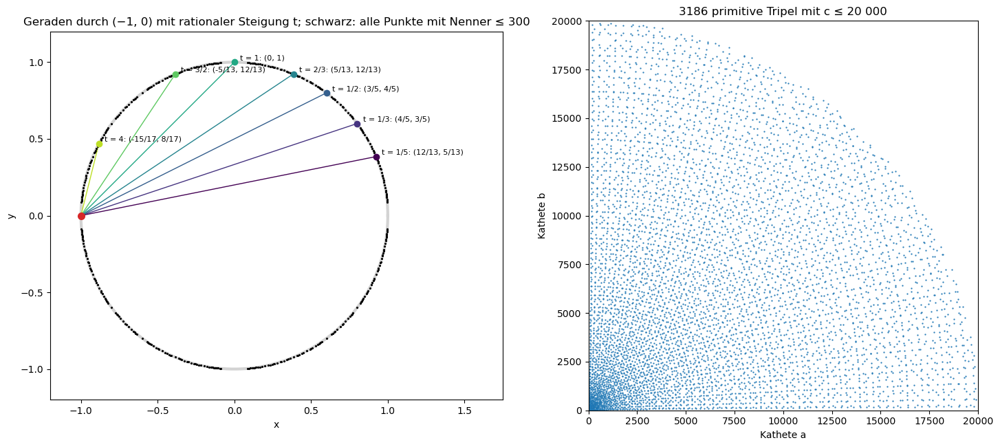

c ≤ 2000: Parametrisierung 319 Tripel, Durchprobieren 319, identisch: True
Primitive Tripel mit c ≤     1,000:     158;  C/(2π) =     159.2
Primitive Tripel mit c ≤    10,000:    1593;  C/(2π) =    1591.5
Primitive Tripel mit c ≤   100,000:   15919;  C/(2π) =   15915.5
Primitive Tripel mit c ≤ 1,000,000:  159139;  C/(2π) =  159154.9

x² + y² = n: rationaler Punkt?
  n =  1: Vorhersage ja   | gefunden: (0/1)² + (1/1)²
  n =  2: Vorhersage ja   | gefunden: (1/1)² + (1/1)²
  n =  3: Vorhersage nein | gefunden: keine Lösung mit Nenner ≤ 300
  n =  4: Vorhersage ja   | gefunden: (0/1)² + (2/1)²
  n =  5: Vorhersage ja   | gefunden: (1/1)² + (2/1)²
  n =  6: Vorhersage nein | gefunden: keine Lösung mit Nenner ≤ 300
  n =  7: Vorhersage nein | gefunden: keine Lösung mit Nenner ≤ 300
  n =  8: Vorhersage ja   | gefunden: (2/1)² + (2/1)²
  n =  9: Vorhersage ja   | gefunden: (0/1)² + (3/1)²
  n = 10: Vorhersage ja   | gefunden: (1/1)² + (3/1)²
  n = 11: Vorhersage nein | gefunden: keine Lösung 

In [43]:
quadrics.rational_points_conics()

**43. Die Gruppenaddition auf einer elliptischen Kurve**

Auf y² = x³ + ax + b schneidet die Gerade durch zwei Punkte die Kurve in einem dritten; gespiegelt ist er ihre Summe. sympy leitet die Formeln her.

Das kubische Polynom aus Gerade und Kurve hat die Summe der Nullstellen λ², daraus folgt der dritte Punkt. Die Tangente liefert die Verdopplung. Mit dem Punkt im Unendlichen als Null ist die Addition eine Gruppe; über 𝔽₆₁ gilt die Assoziativität auf allen 314 432 Tripeln.

x³ + ax + b − (λx + ν)² hat die Koeffizienten (x³, x², x, 1):


[1, -lambda**2, a - 2*lambda*nu, b - nu**2]

Steigung der Tangente an y² = x³ + ax + b:


Eq(dy/dx, (a + 3*x**2)/(2*y))

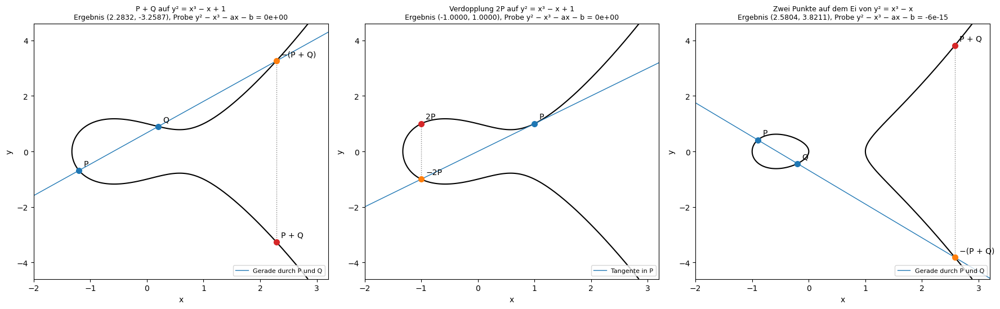

y² = x³ + 17: 16 ganzzahlige Punkte, 4096 Tripel (P + Q) + R = P + (Q + R) exakt geprüft, Abweichungen oder Punkte neben der Kurve: 0; größter Nenner von x: 29 Stellen


In [44]:
quadrics.group_law()

**44. Rationale Punkte und Höhe**

Die Höhe eines rationalen Punktes misst die Größe seiner Zähler und Nenner. Verglichen werden ein Kreis (Grad 2), eine elliptische Kurve (Grad 3) und eine Quartik (Grad 4).

Auf dem Kreis gibt es bis zur Höhe 10⁶ über eine Million rationale Punkte, auf der elliptischen Kurve y² = x³ − 2 nur 6, auf der Quartik a⁴ + b⁴ = c⁴ keine außer den trivialen (Fermat). Die Höhe der Vielfachen nP wächst wie n²: Die Zähler von 30P haben 528 Stellen.

Alle Punkte mit H(x) ≤ 20 000 auf y² = x³ − 2 (nur y ≥ 0): ['(3, 5)', '(129/100, 383/1000)']
Zum Vergleich: x(P) = 3, x(2P) = 129/100 , H(x(3P)) = 164323


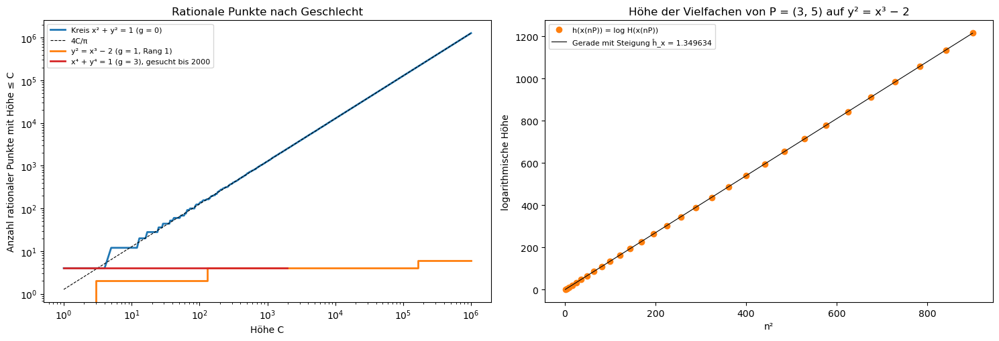

n =  1: H(x(nP)) hat    1 Stellen, h/n² = 1.098612
n =  2: H(x(nP)) hat    3 Stellen, h/n² = 1.214953
n =  3: H(x(nP)) hat    6 Stellen, h/n² = 1.334399
n =  4: H(x(nP)) hat   10 Stellen, h/n² = 1.348363
n = 10: H(x(nP)) hat   59 Stellen, h/n² = 1.346204
n = 30: H(x(nP)) hat  528 Stellen, h/n² = 1.349567
Kanonische Höhe aus der Anpassung: ĥ_x(P) = 1.349634 (Silverman-Normierung ĥ = 0.674817); Abweichung h − ĥ_x n² für n ≥ 6 höchstens 0.593
Kreis: N(10⁶) = 1273116, 4C/π = 1273240;  elliptische Kurve: N(10⁶) = 6;  Quartik: primitive Lösungen von a⁴ + b⁴ = c⁴ mit c ≤ 2000: [(0, 1, 1), (1, 0, 1)]


In [45]:
quadrics.heights()

**45. Elliptische Kurven über endlichen Körpern: Hasse und Sato-Tate**

Über 𝔽_p hat eine elliptische Kurve etwa p + 1 Punkte, und die Abweichung a_p ist nach Hasse höchstens 2√p. Wie sich a_p über die Primzahlen verteilt, sagt die Sato-Tate-Vermutung.

Alle a_p bis 30 000 liegen innerhalb von ±2√p. Normiert folgen sie für eine typische Kurve der Halbkreisverteilung von Sato-Tate; eine Kurve mit komplexer Multiplikation verhält sich anders: Bei ihr ist a_p für alle p ≡ 3 mod 4 genau null.

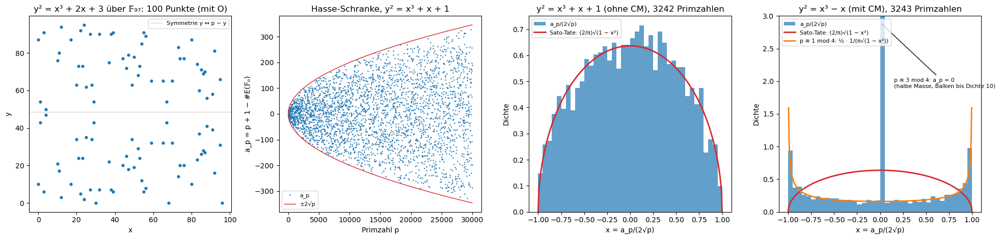

y² = x³ + x + 1 (ohne CM) : max |a_p|/(2√p) = 0.9997;  ⟨x²⟩ = 0.2440 (Sato-Tate 0.25), ⟨x⁴⟩ = 0.1211 (0.125);  Anteil a_p = 0: 0.004, davon bei p ≡ 3 mod 4: 0.006
y² = x³ − x (mit CM)      : max |a_p|/(2√p) = 0.9999;  ⟨x²⟩ = 0.2449 (Sato-Tate 0.25), ⟨x⁴⟩ = 0.1824 (0.125);  Anteil a_p = 0: 0.503, davon bei p ≡ 3 mod 4: 1.000


y² = x³ + 2x + 3 über 𝔽₆₁: 68 Punkte, Assoziativität auf allen 314432 Tripeln, Verstöße: 0; größte Punktordnung 68, die Gruppe ist zyklisch ({2: 2, 17: 1})


In [46]:
quadrics.finite_field_curves()

**46. ECDH und das diskrete Logarithmusproblem**

Alice und Bob tauschen über eine elliptische Kurve einen gemeinsamen Schlüssel aus, ohne ihn zu senden. Sicher ist das, weil aus kG das k nicht zu finden ist.

Beide kommen auf denselben Punkt. Die Vielfachen kG springen ohne erkennbare Ordnung über das Gitter. Ein Skalarprodukt mit 256-Bit-Schlüssel braucht nur 256 Verdopplungen und rund 140 Additionen, das Rückwärtsrechnen nach heutigem Wissen 2¹²⁸ Schritte.

Kurve y² = x³ + 22391x + 2830 über 𝔽₅₁₁₉₇, Ordnung N = 50993 (prim), Erzeuger G = (26947, 21739)
Alice: geheim a = 3591, öffentlich A = aG = (18095, 50361)
Bob:   geheim b = 24827, öffentlich B = bG = (26477, 29245)
aB = (34504, 48161), bA = (34504, 48161), abG = (34504, 48161)


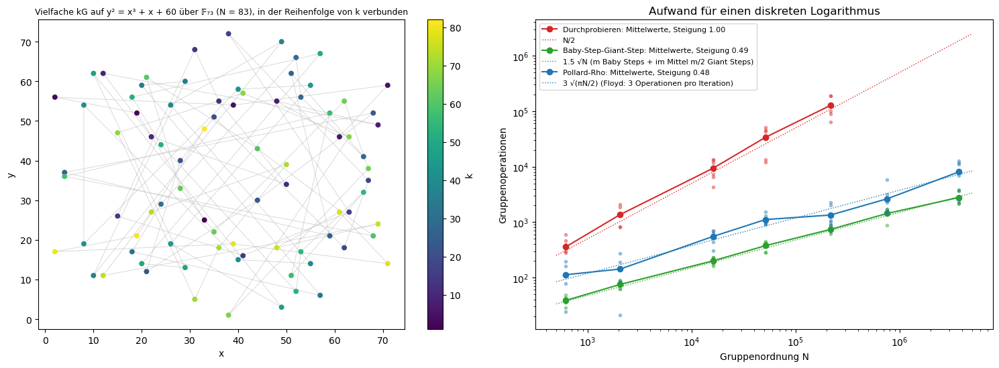

Durchprobieren       : Steigung der Mittelwerte 1.000;  gemessen / Vorhersage (N/2) im Mittel 1.23 über 30 Logarithmen
Baby-Step-Giant-Step : Steigung der Mittelwerte 0.494;  gemessen / Vorhersage (1.5 √N) im Mittel 1.06 über 42 Logarithmen
Pollard-Rho          : Steigung der Mittelwerte 0.484;  gemessen / Vorhersage (3 √(πN/2)) im Mittel 1.03 über 42 Logarithmen

secp256k1: G auf der Kurve: True;  N prim: True;  N·G = O: True
Ein Skalarprodukt mit 256-Bit-Schlüssel: 256 Verdopplungen und 142 Additionen, 12.0 ms in reinem Python
Gemeinsames Geheimnis gleich: True
Pollard-Rho bräuchte √(πN/2) = 4.26e+38 Operationen, bei 10¹² Operationen pro Sekunde 1.4e+19 Jahre


In [47]:
quadrics.ecdh()

**47. Shors Algorithmus für den diskreten Logarithmus**

Ein Quantencomputer findet k aus kG mit Shors Algorithmus: Eine Überlagerung aller aP + bQ, eine Messung und eine Quanten-Fourier-Transformation verraten k. Simuliert auf einer winzigen Kurve mit 47 Punkten.

Nach der Fourier-Transformation liegt die ganze Wahrscheinlichkeit auf einer Geraden, deren Steigung k ist. Für eine 256-Bit-Kurve bräuchte man nach Roetteler et al. (2017) 2330 logische Qubits und rund 10¹¹ Toffoli-Gatter; deshalb wechselt die Kryptographie zu Verfahren auf Gittern.

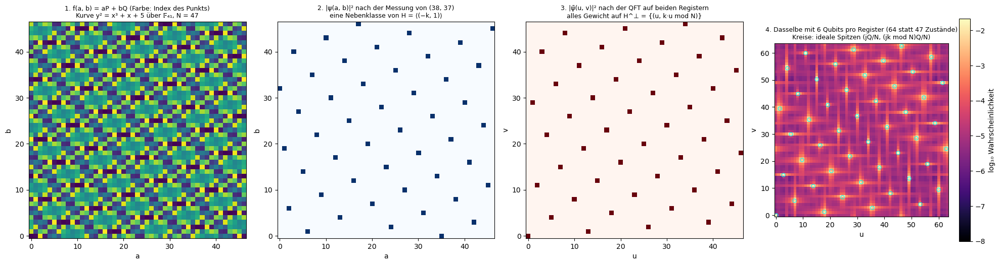

Kurve y² = x³ + x + 5 über 𝔽₄₁: N = 47 (prim); P = (0, 13), Q = (36, 30); geheim k = 29
Gemessen im dritten Register: (38, 37); Wahrscheinlichkeit auf der Geraden v ≡ k·u: 1.000000000000001
Verteilung mit und ohne Messung des dritten Registers, größte Differenz: 5.2e-17
12 Messungen (u, v) → k = v·u⁻¹ mod N: (9,26)→29, (38,21)→29, (7,15)→29, (24,38)→29, (6,33)→29, (32,35)→29, (39,3)→29, (19,34)→29, (44,7)→29, (38,21)→29, (15,12)→29, (27,31)→29
Erfolgswahrscheinlichkeit pro Durchlauf: ideal 0.9787 (Theorie 1 − 1/N = 0.9787)
  mit 6 Qubits pro Register: Erfolg nach Rundung 0.7391  (Gesamtwahrscheinlichkeit 1.000000000000)
  mit 7 Qubits pro Register: Erfolg nach Rundung 0.8219  (Gesamtwahrscheinlichkeit 1.000000000000)
  mit 8 Qubits pro Register: Erfolg nach Rundung 0.9097  (Gesamtwahrscheinlichkeit 1.000000000000)


  mit 9 Qubits pro Register: Erfolg nach Rundung 0.9415  (Gesamtwahrscheinlichkeit 1.000000000000)

QFT-Schaltung mit 6 Qubits: 6 Hadamard, 15 kontrollierte Phasen, 3 SWAPs; größte Abweichung von der DFT-Matrix 5.1e-15
Für eine 256-Bit-Kurve (Roetteler et al. 2017): 2330 logische Qubits, Toffoli-Gatter höchstens (448 log₂n + 4090) n³ = 1.29e+11; die QFT auf 257 Qubits hat dagegen nur 32,896 kontrollierte Phasen


In [48]:
quadrics.shor_dlog()